In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.api.types import is_numeric_dtype
import plotly.express as px
import seaborn as sns
import math

# 1. Load and inspect the data

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/salioudunn11/Fitness_Prediction/main/gym_members_exercise_tracking.csv")

In [3]:
display(df.head())

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.3,1.71,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20
1,46,Female,74.9,1.53,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00
2,32,Female,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71
3,25,Male,53.2,1.70,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41
4,38,Male,46.1,1.79,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39


In [4]:
display(df.shape)

(973, 15)

In [5]:
display(df.dtypes)

Age                                int64
Gender                               str
Weight (kg)                      float64
Height (m)                       float64
Max_BPM                            int64
Avg_BPM                            int64
Resting_BPM                        int64
Session_Duration (hours)         float64
Calories_Burned                  float64
Workout_Type                         str
Fat_Percentage                   float64
Water_Intake (liters)            float64
Workout_Frequency (days/week)      int64
Experience_Level                   int64
BMI                              float64
dtype: object

# 2. Summary Statistics

In [6]:
display(df.describe())

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,973.000000,973.000000,973.00000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000
mean,38.683453,73.854676,1.72258,179.883864,143.766701,62.223022,1.256423,905.422405,24.976773,2.626619,3.321686,1.809866,24.912127
std,12.180928,21.207500,0.12772,11.525686,14.345101,7.327060,0.343033,272.641516,6.259419,0.600172,0.913047,0.739693,6.660879
min,18.000000,40.000000,1.50000,160.000000,120.000000,50.000000,0.500000,303.000000,10.000000,1.500000,2.000000,1.000000,12.320000
25%,28.000000,58.100000,1.62000,170.000000,131.000000,56.000000,1.040000,720.000000,21.300000,2.200000,3.000000,1.000000,20.110000
50%,40.000000,70.000000,1.71000,180.000000,143.000000,62.000000,1.260000,893.000000,26.200000,2.600000,3.000000,2.000000,24.160000
75%,49.000000,86.000000,1.80000,190.000000,156.000000,68.000000,1.460000,1076.000000,29.300000,3.100000,4.000000,2.000000,28.560000
max,59.000000,129.900000,2.00000,199.000000,169.000000,74.000000,2.000000,1783.000000,35.000000,3.700000,5.000000,3.000000,49.840000


In [7]:
# it seems redundant but we wanted to see this four vlaues in clear format
display(df.describe().T[['mean', 'std', 'min', 'max']].round(2))

,mean,std,min,max
Age,38.68,12.18,18.00,59.00
Weight (kg),73.85,21.21,40.00,129.90
Height (m),1.72,0.13,1.50,2.00
Max_BPM,179.88,11.53,160.00,199.00
Avg_BPM,143.77,14.35,120.00,169.00
Resting_BPM,62.22,7.33,50.00,74.00
Session_Duration (hours),1.26,0.34,0.50,2.00
Calories_Burned,905.42,272.64,303.00,1783.00
Fat_Percentage,24.98,6.26,10.00,35.00
Water_Intake (liters),2.63,0.60,1.50,3.70


In [8]:
display(df['Workout_Type'].value_counts())

Workout_Type
Strength    258
Cardio      255
Yoga        239
HIIT        221
Name: count, dtype: int64

In [9]:
display(df['Gender'].value_counts())

Gender
Male      511
Female    462
Name: count, dtype: int64

# 3. Data Visualization

### 3.1 Calories Burned Distribution

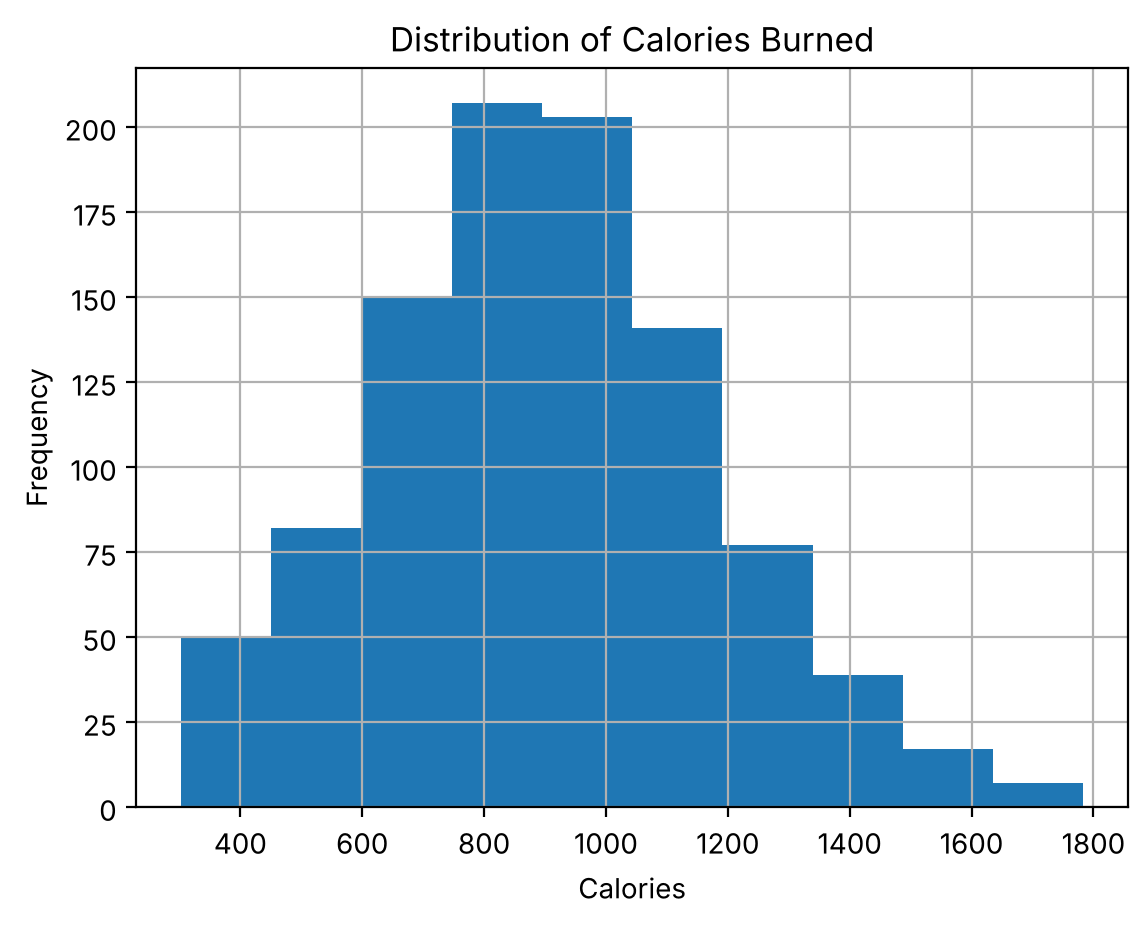

In [10]:
df['Calories_Burned'].hist(bins=10)
plt.title("Distribution of Calories Burned")
plt.xlabel("Calories")
plt.ylabel("Frequency")
plt.show()

### 3.2 Numerical Attribute Boxplots

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


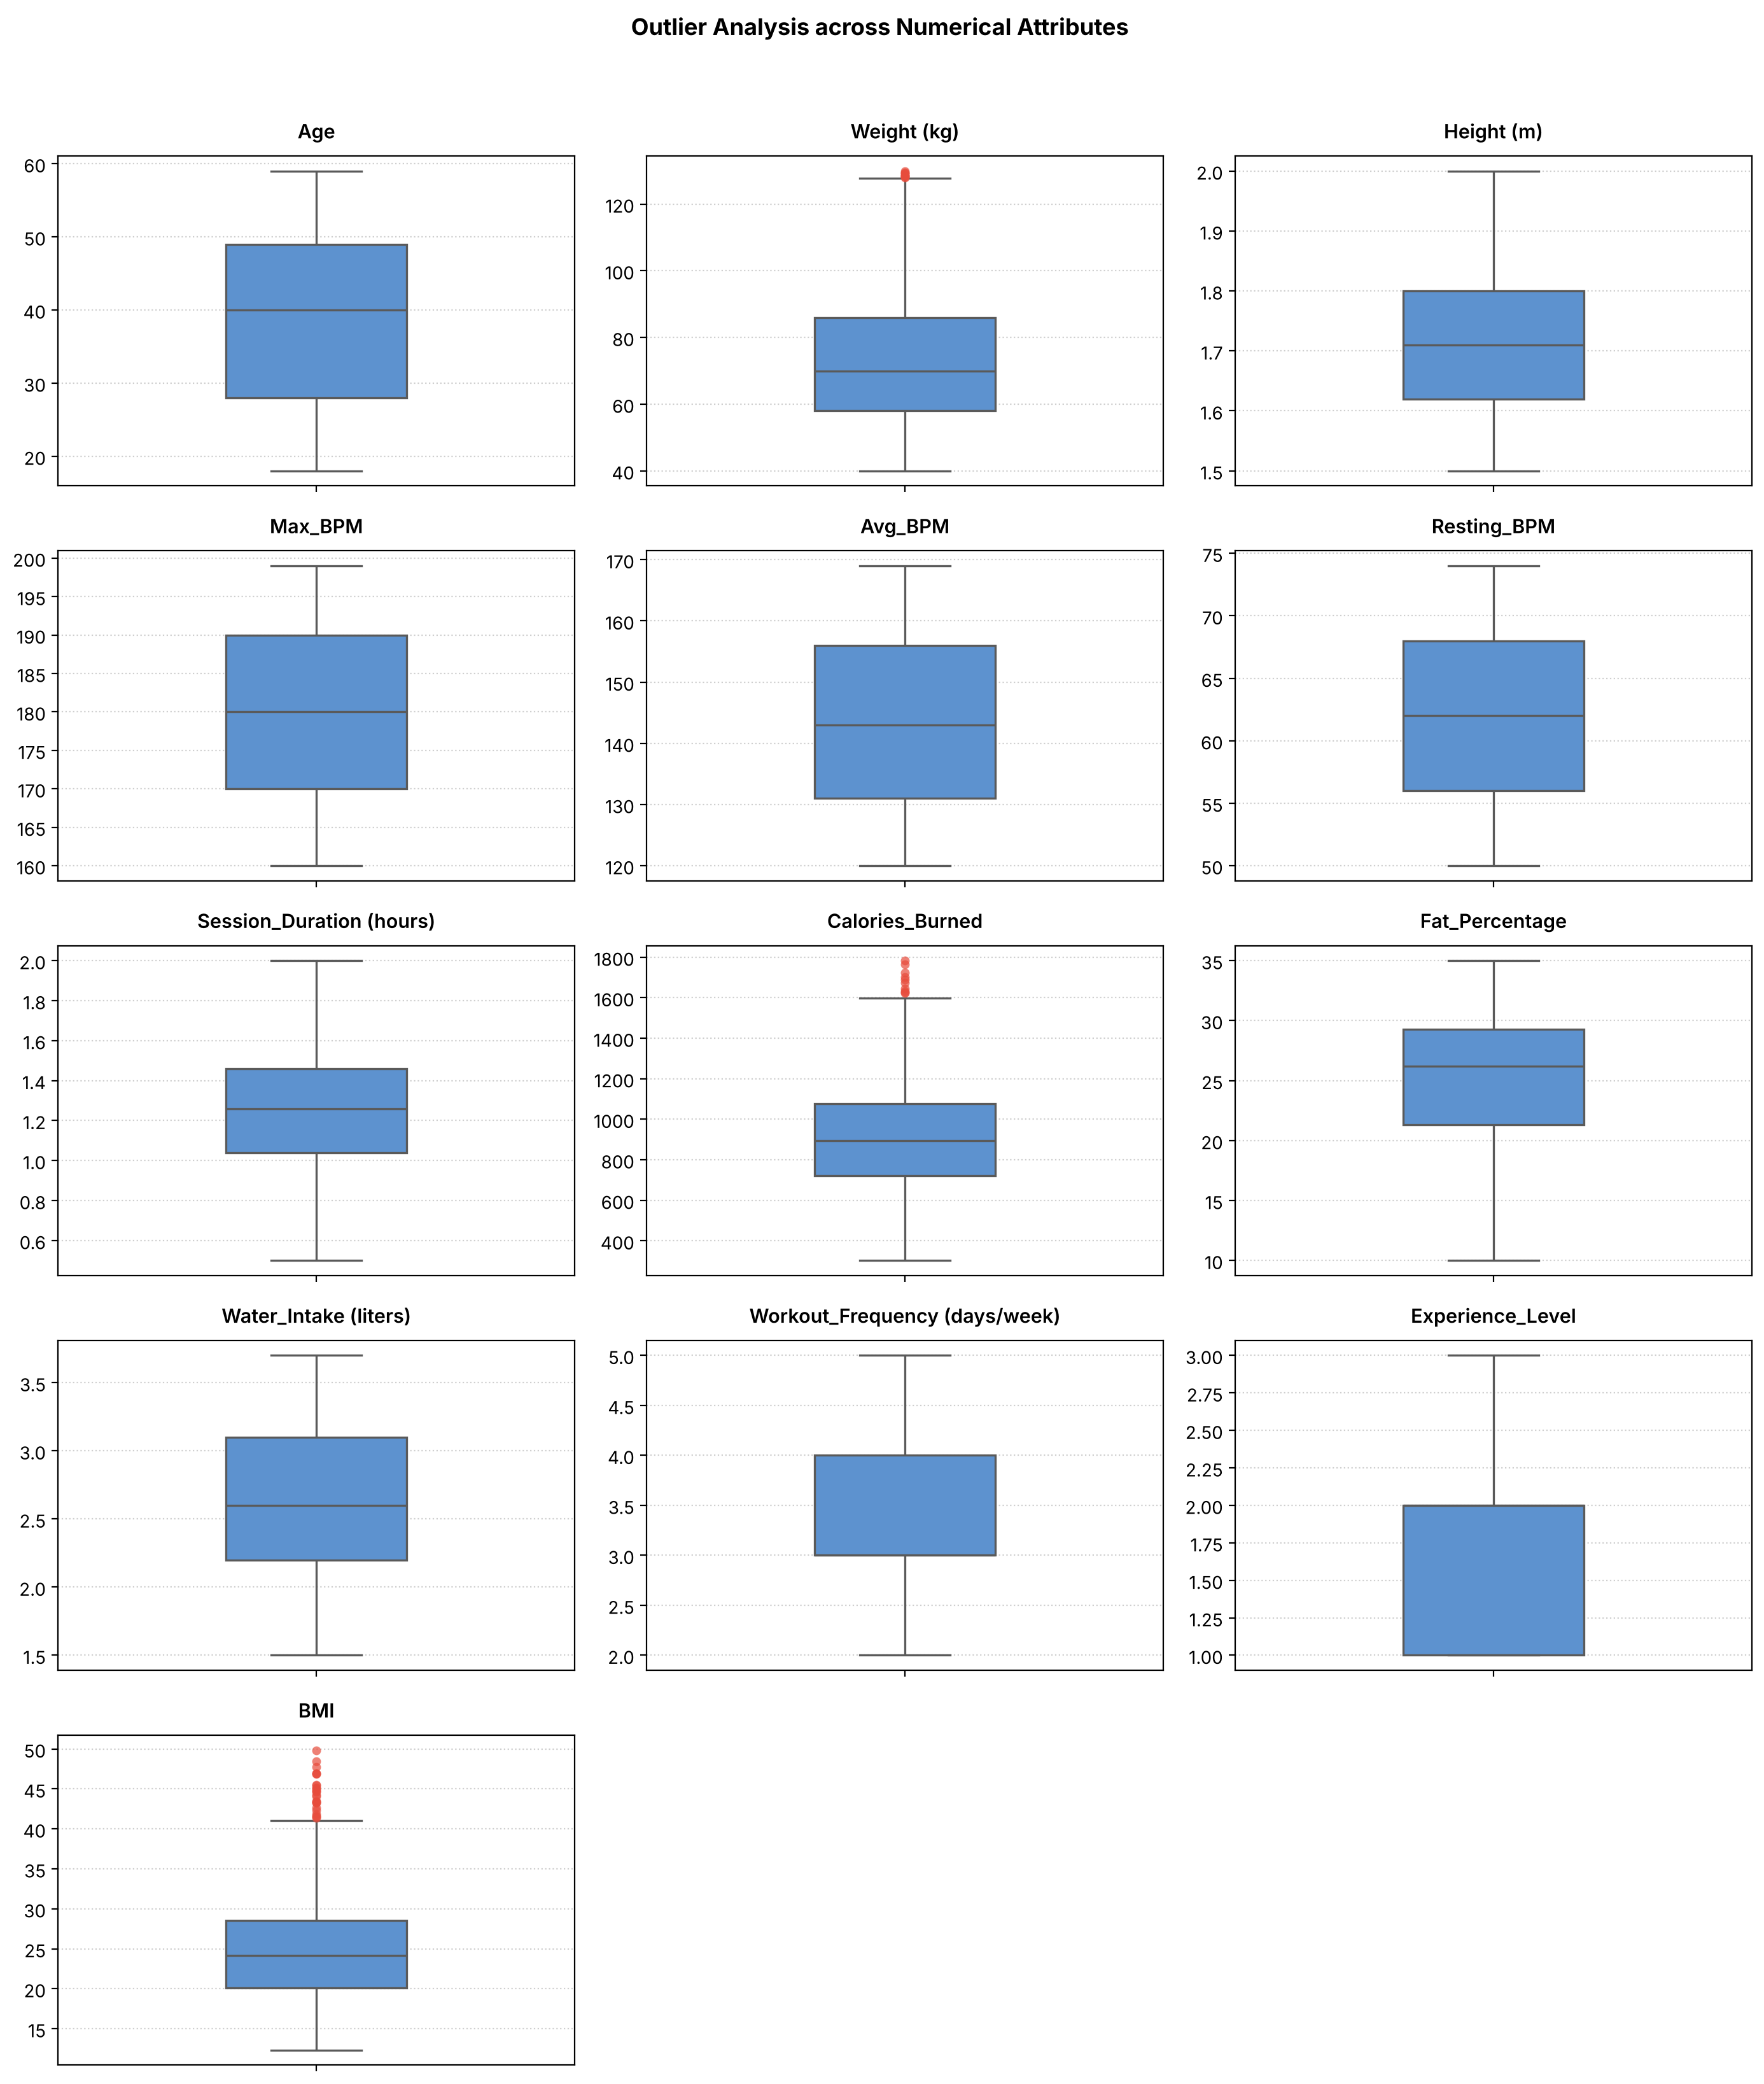

In [11]:
numeric_cols = [
    'Age', 'Weight (kg)', 'Height (m)', 'Max_BPM',
    'Avg_BPM', 'Resting_BPM', 'Session_Duration (hours)',
    'Calories_Burned', 'Fat_Percentage', 'Water_Intake (liters)',
    'Workout_Frequency (days/week)','Experience_Level', 'BMI'
]
# Keep only columns actually present in df
plot_cols = [c for c in numeric_cols if c in df.columns]

# 2. Setup grid dimensions
n_cols = 3
n_rows = math.ceil(len(plot_cols) / n_cols)

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(14, n_rows * 3.2))
axes = axes.flatten()

# Custom style for outlier markers
flierprops = dict(marker='o', markersize=5, markerfacecolor='#e74c3c', markeredgecolor='none', alpha=0.7)

for i, col in enumerate(plot_cols):
    ax = axes[i]

    # width=0.35 keeps boxes sleek rather than filling the entire card
    sns.boxplot(
        y=df[col],
        ax=ax,
        width=0.35,
        color='#4a90e2',
        linewidth=1.2,
        flierprops=flierprops
    )

    # Clean styling
    ax.set_title(col, fontsize=11, fontweight='semibold', pad=10)
    ax.set_ylabel("")
    ax.grid(axis='y', linestyle=':', alpha=0.6)

# Remove unused axes in the grid
for j in range(len(plot_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Outlier Analysis across Numerical Attributes", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3.3 Correlation Matrix

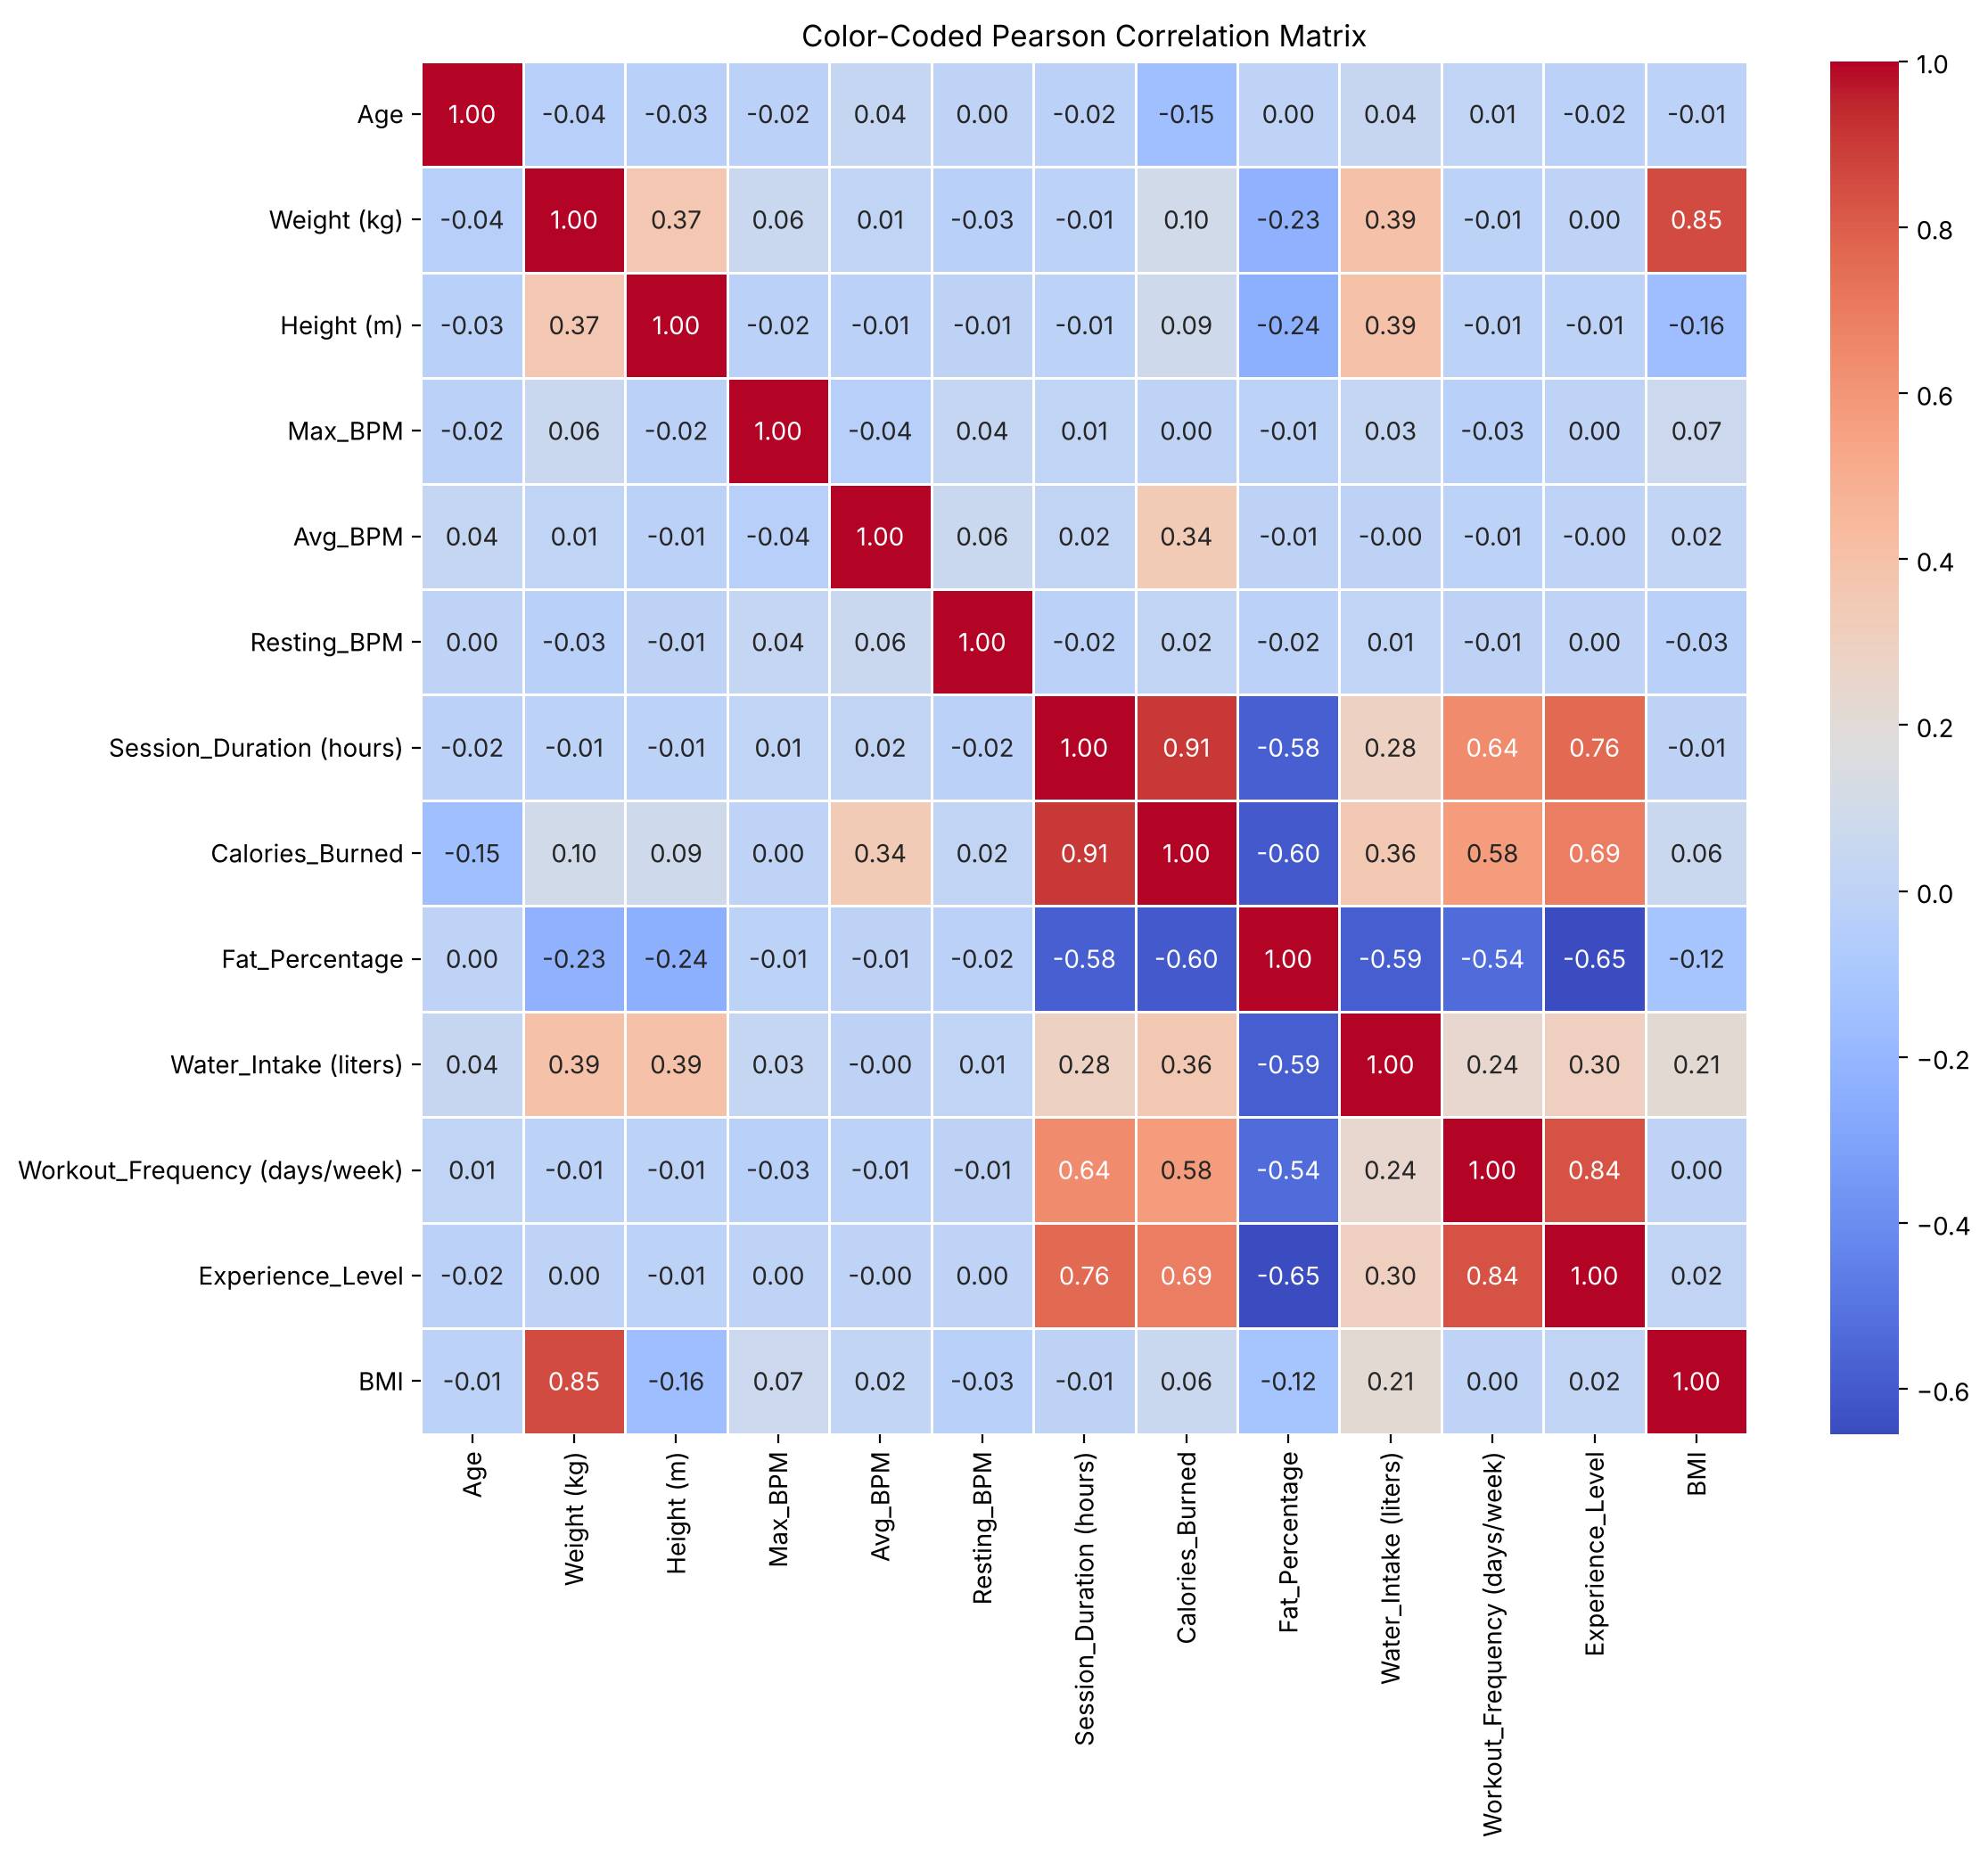

In [12]:
plt.figure(figsize=(12, 10))
numeric_cols = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_cols.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Color-Coded Pearson Correlation Matrix')
plt.show()

### 3.4 Calories by Workout Type & Gender

In [13]:
print("Correlation of each feature with 'Calories_Burned':")
display(correlation_matrix['Calories_Burned'].round(2).sort_values(ascending=False))

Correlation of each feature with 'Calories_Burned':


Calories_Burned                  1.00
Session_Duration (hours)         0.91
Experience_Level                 0.69
Workout_Frequency (days/week)    0.58
Water_Intake (liters)            0.36
Avg_BPM                          0.34
Weight (kg)                      0.10
Height (m)                       0.09
BMI                              0.06
Resting_BPM                      0.02
Max_BPM                          0.00
Age                             -0.15
Fat_Percentage                  -0.60
Name: Calories_Burned, dtype: float64

###3.5 Categorical vs. Target Analysis

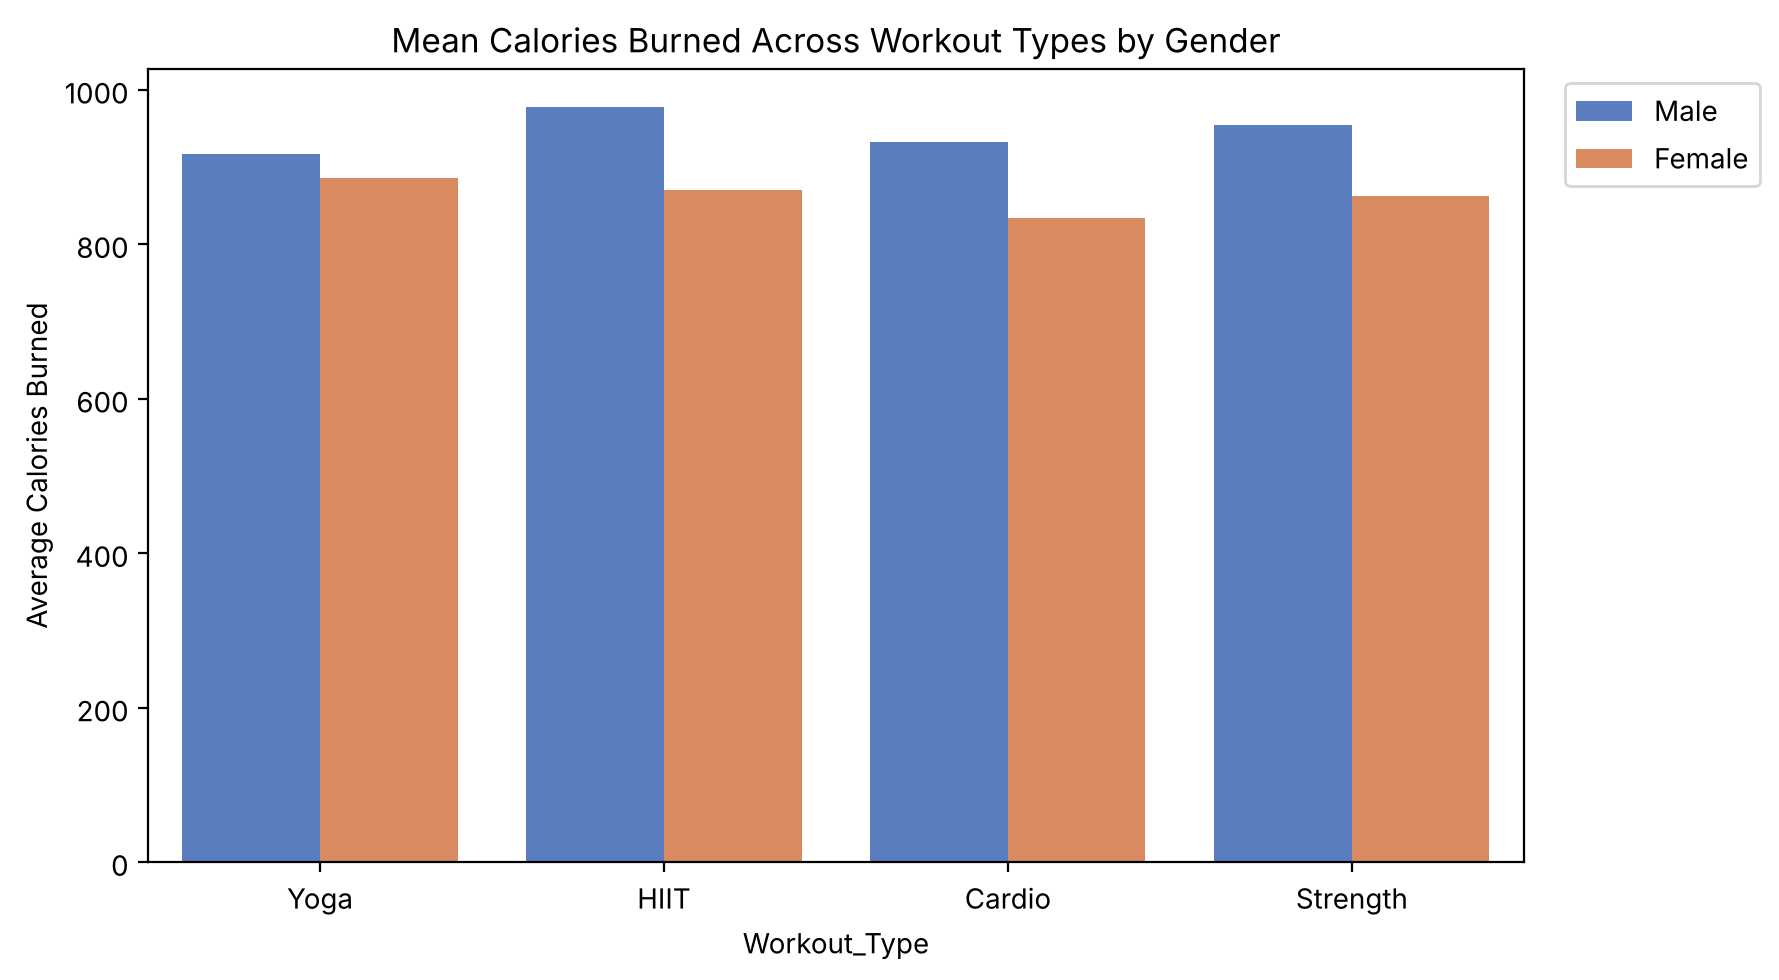

In [14]:
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x='Workout_Type', y='Calories_Burned', hue='Gender', errorbar=None, palette='muted')
plt.title("Mean Calories Burned Across Workout Types by Gender")
plt.ylabel("Average Calories Burned")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [15]:
fig = px.scatter_matrix(
    df,
    dimensions=['Session_Duration (hours)', 'Calories_Burned', 'Avg_BPM', 'Fat_Percentage'],
    color='Workout_Type',
    title="Scatter Matrix of Gym Attributes by Workout Type",
    width=900,
    height=900
)
fig.show()

# 4. Data Cleaning and Preprocessing

### 4.1 Missing Values & Duplicates

In [16]:
display(df.isna().sum())

Age                              0
Gender                           0
Weight (kg)                      0
Height (m)                       0
Max_BPM                          0
Avg_BPM                          0
Resting_BPM                      0
Session_Duration (hours)         0
Calories_Burned                  0
Workout_Type                     0
Fat_Percentage                   0
Water_Intake (liters)            0
Workout_Frequency (days/week)    0
Experience_Level                 0
BMI                              0
dtype: int64

In [17]:
display(df.duplicated().sum())

np.int64(0)

### 4.2 Unit Conversions

In [18]:
# 1. Create an independent working copy to preserve raw data
df_clean = df.copy()

# 2. Add imperial conversions
df_clean['Weight (lb)'] = (df_clean['Weight (kg)'] * 2.20462).round(2)
df_clean['Height (in)'] = (df_clean['Height (m)'] * 39.3701).round(2)

# 3. Drop the metric columns
df_clean = df_clean.drop(columns=['Weight (kg)', 'Height (m)'])

# 4. Inspect result
display(df_clean.head())

,Age,Gender,Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI,Weight (lb),Height (in)
0,56,Male,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20,194.67,67.32
1,46,Female,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00,165.13,60.24
2,32,Female,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71,150.13,65.35
3,25,Male,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41,117.29,66.93
4,38,Male,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39,101.63,70.47


### 4.3 Z-Score Outlier Detection

In [19]:
num_data = df_clean.select_dtypes(include=[np.number])
Z = (num_data - num_data.mean()) / num_data.std()

def highlight_outliers(val):
    if abs(val) > 3:
        return 'background-color: #ff4d4d; color: white; font-weight: bold;'
    return 'color: #555555;'

# Filter rows that actually contain at least one outlier to keep it concise
outlier_rows = Z[(Z.abs() > 3).any(axis=1)]

styled_outliers = (
    outlier_rows.style
    .map(highlight_outliers)
    .format("{:+.2f}")
    .set_caption("🚩 Records with Extreme Outliers (|Z| > 3.0)")
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold')]},
        {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-size', '14px'), ('font-weight', 'bold'), ('margin-bottom', '8px')]}
    ])
)

display(styled_outliers)

,Age,Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI,Weight (lb),Height (in)
133,-1.45,+1.40,+1.06,-0.30,+0.36,+1.11,+0.77,+1.29,-0.35,+0.26,+3.08,+2.42,-0.49
251,-0.47,-1.20,-0.96,-0.99,-0.63,-0.59,+0.02,-0.38,-0.35,+0.26,+3.04,+2.03,-0.88
261,+1.50,-1.64,-0.75,+1.47,-0.86,-1.00,-0.67,-0.88,-1.45,-1.09,+3.42,+2.50,-0.73
291,+1.34,-0.16,+1.48,-1.40,-0.37,+0.06,-0.73,-0.04,+0.74,+0.26,+3.09,+2.57,-0.33
470,-0.38,-1.64,-0.54,+0.52,+0.45,+0.55,+0.42,+0.29,-0.35,+0.26,+3.30,+2.39,-0.73
511,+0.03,+0.96,+1.13,+1.33,+2.05,+3.01,-2.36,+1.46,+1.84,+1.61,+0.17,+0.58,+0.76
687,-1.70,-0.68,+0.64,-0.30,+0.59,+1.19,-0.70,-0.71,-0.35,+0.26,+3.04,+2.45,-0.41
710,-0.06,-1.64,+1.48,+0.38,+0.24,+1.14,-0.60,-0.54,+0.74,+0.26,+3.31,+2.33,-0.80
712,-1.62,-0.51,+1.76,-0.03,+1.88,+3.16,-2.38,+1.46,+1.84,+1.61,-0.52,+0.40,+1.86
854,+0.76,+1.14,+1.62,-0.03,-0.57,-0.11,-0.57,+0.46,+0.74,+0.26,+3.74,+2.61,-0.88


In [20]:
outlier_mask = (Z.abs() > 3).any(axis=1)
outliers = df_clean.loc[outlier_mask]
print(f'Number of Total Outlier: {len(outliers)}')

Number of Total Outlier: 13


# 5. Discretization

### 5.1 Equal-Width Binning

In [21]:
cal_bins_width = pd.cut(df_clean['Calories_Burned'], 4)
print("Equal-width bins for Calories_Burned:")
display(cal_bins_width.value_counts(sort=False))

Equal-width bins for Calories_Burned:


Calories_Burned
(301.52, 673.0]     188
(673.0, 1043.0]     506
(1043.0, 1413.0]    240
(1413.0, 1783.0]     39
Name: count, dtype: int64

In [22]:
fat_bins_width = pd.cut(df_clean['Fat_Percentage'], 4)
print("Equal-width bins for Fat_Percentage:")
display(fat_bins_width.value_counts(sort=False))

Equal-width bins for Fat_Percentage:


Fat_Percentage
(9.975, 16.25]    120
(16.25, 22.5]     172
(22.5, 28.75]     392
(28.75, 35.0]     289
Name: count, dtype: int64

### 5.2 Equal-Frequency Binning

In [23]:
cal_bins_freq = pd.qcut(df_clean['Calories_Burned'], 4)
print("Equal-frequency bins for Calories_Burned:")
display(cal_bins_freq.value_counts(sort=False))

Equal-frequency bins for Calories_Burned:


Calories_Burned
(302.999, 720.0]    245
(720.0, 893.0]      242
(893.0, 1076.0]     243
(1076.0, 1783.0]    243
Name: count, dtype: int64

In [24]:
fat_bins_freq = pd.qcut(df_clean['Fat_Percentage'], 4)
print("Equal-frequency bins for Fat_Percentage:")
display(fat_bins_freq.value_counts(sort=False))

Equal-frequency bins for Fat_Percentage:


Fat_Percentage
(9.999, 21.3]    253
(21.3, 26.2]     236
(26.2, 29.3]     245
(29.3, 35.0]     239
Name: count, dtype: int64

---

# Phase 3: Model Building & Evaluation

This section reproduces every number and chart in the **CST-3502 Modeling Presentation (fixed version)**.

**Ground rules used throughout**
- Target: `High_Calorie = 1` when `Calories_Burned` is above the median (893), so the classes are 50/50.
- One stratified 80/20 split (`random_state=42`): 778 training sessions, 195 test sessions.
- All tuning and cross-validation use the **training set only**. The test set is used once per model, for the final score.
- 5-fold stratified CV with `shuffle=True, random_state=42`.

In [25]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from scipy.special import logsumexp
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve, auc)

RS = 42
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

def report(name, y_true, y_pred, y_score=None):
    out = {'Model': name,
           'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision_score(y_true, y_pred),
           'Recall': recall_score(y_true, y_pred), 'F1': f1_score(y_true, y_pred)}
    if y_score is not None:
        out['ROC AUC'] = roc_auc_score(y_true, y_score)
    return out

## 3.0 Target and train/test split

In [26]:
data = df_clean.copy()
median_cal = data['Calories_Burned'].median()
y = (data['Calories_Burned'] > median_cal).astype(int)
X = data.drop(columns=['Calories_Burned'])          # never use the target's source column as a feature

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS, stratify=y)
print(f'Median calories: {median_cal:.0f}')
print(f'Train: {len(X_train)}  Test: {len(X_test)}')
print('Train class counts:', y_train.value_counts().to_dict())

Median calories: 893
Train: 778  Test: 195
Train class counts: {0: 389, 1: 389}


## 3.1 Decision Tree (slides 2–4)
Trees need no scaling; Gender and Workout_Type are label-encoded.

In [27]:
def encode_for_tree(df):
    out = df.copy()
    out['Gender'] = out['Gender'].astype('category').cat.codes
    out['Workout_Type'] = out['Workout_Type'].astype('category').cat.codes
    return out

Xtr_dt, Xte_dt = encode_for_tree(X_train), encode_for_tree(X_test)
dt_params = dict(criterion='entropy', min_samples_split=4, min_samples_leaf=2, random_state=RS)

# Depth tuning: 5-fold CV repeated 10 times, training set only
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RS)
rows = []
for d in [2, 3, 4, 5, 6, 8, None]:
    r = cross_validate(DecisionTreeClassifier(max_depth=d, **dt_params), Xtr_dt, y_train, cv=rcv, return_train_score=True)
    leaves = DecisionTreeClassifier(max_depth=d, **dt_params).fit(Xtr_dt, y_train).get_n_leaves()
    rows.append({'max_depth': str(d), 'leaves': leaves, 'cv_train': r['train_score'].mean(),
                 'cv_val': r['test_score'].mean(), 'cv_std': r['test_score'].std()})
depth_df = pd.DataFrame(rows)
display(depth_df.round(4))

,max_depth,leaves,cv_train,cv_val,cv_std
0,2,4,0.8624,0.8544,0.0225
1,3,7,0.8805,0.8539,0.0228
2,4,12,0.9176,0.8677,0.0216
3,5,18,0.9390,0.8746,0.0218
4,6,27,0.9635,0.8815,0.0239
5,8,38,0.9877,0.8922,0.0232
6,None,44,0.9903,0.8907,0.0214


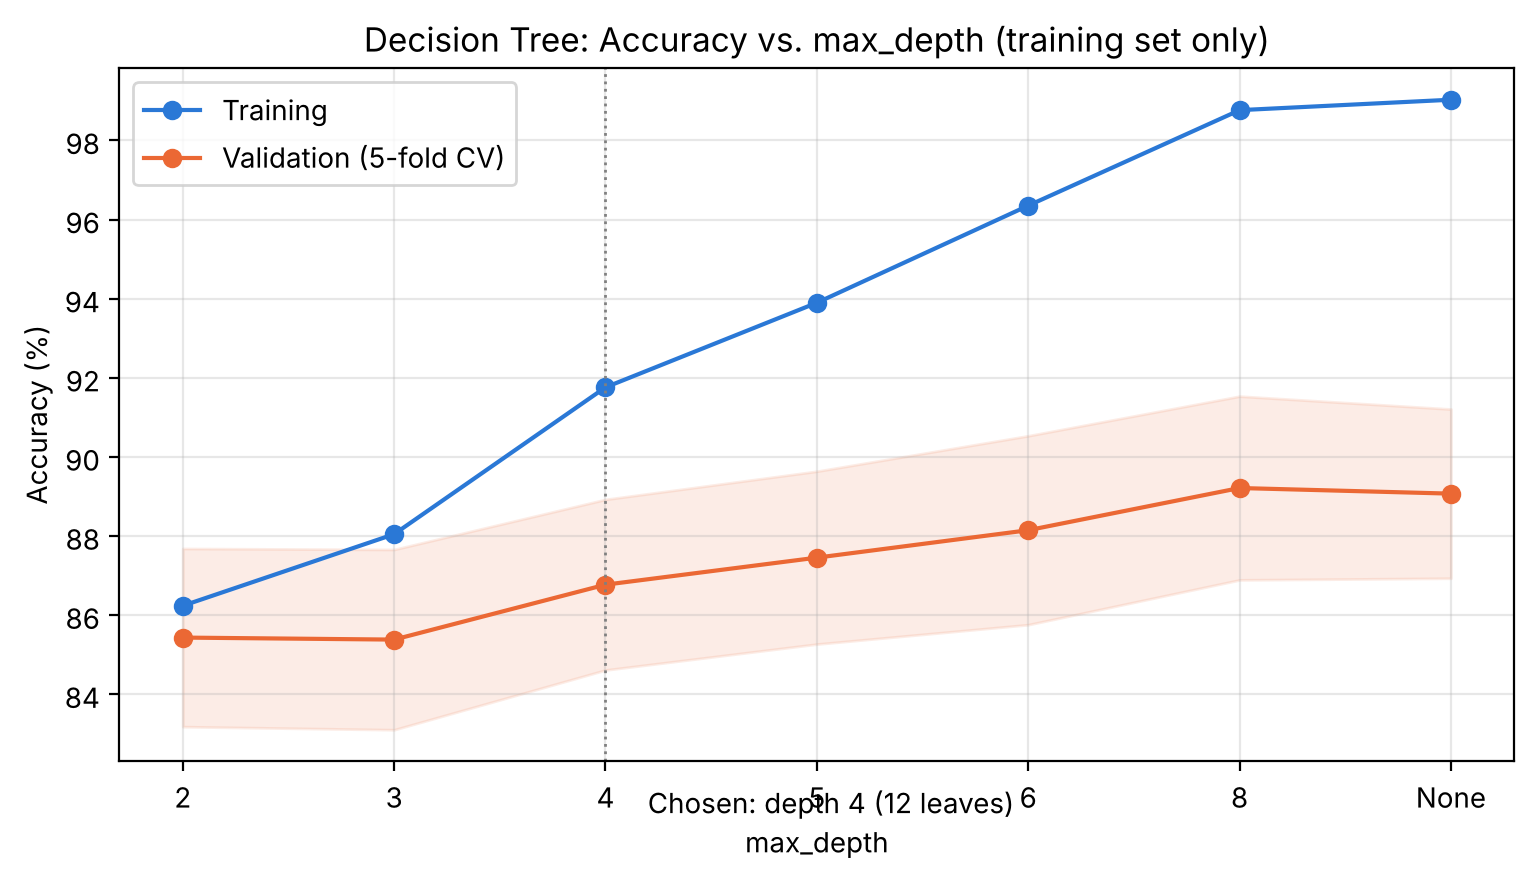

Deeper trees score ~2 points higher in CV but have ~3x as many leaves; depth 4 is chosen for interpretability.


In [28]:
x = np.arange(len(depth_df))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(x, depth_df.cv_train*100, 'o-', color='#2a78d6', label='Training')
ax.plot(x, depth_df.cv_val*100, 'o-', color='#eb6834', label='Validation (5-fold CV)')
ax.fill_between(x, (depth_df.cv_val-depth_df.cv_std)*100, (depth_df.cv_val+depth_df.cv_std)*100, color='#eb6834', alpha=.12)
ax.axvline(2, color='gray', ls=':', lw=1)
ax.annotate('Chosen: depth 4 (12 leaves)', (2, depth_df.cv_val[2]*100), xytext=(2.2, 81))
ax.set_xticks(x); ax.set_xticklabels(depth_df.max_depth); ax.set_xlabel('max_depth'); ax.set_ylabel('Accuracy (%)')
ax.set_title('Decision Tree: Accuracy vs. max_depth (training set only)'); ax.legend(); ax.grid(alpha=.3)
plt.show()
print('Deeper trees score ~2 points higher in CV but have ~3x as many leaves; depth 4 is chosen for interpretability.')

In [29]:
dt = DecisionTreeClassifier(max_depth=4, **dt_params).fit(Xtr_dt, y_train)
cv_dt = cross_validate(DecisionTreeClassifier(max_depth=4, **dt_params), Xtr_dt, y_train, cv=cv5,
                       scoring=['accuracy', 'precision', 'recall'])
print(f"Train accuracy: {dt.score(Xtr_dt, y_train):.4f}")
print(f"5-fold CV (training set): acc {cv_dt['test_accuracy'].mean():.4f}  "
      f"prec {cv_dt['test_precision'].mean():.4f}  rec {cv_dt['test_recall'].mean():.4f}")
print(f"Test accuracy: {dt.score(Xte_dt, y_test):.4f}")
imp = pd.Series(dt.feature_importances_, Xtr_dt.columns)
display(imp[imp > 0].sort_values(ascending=False).round(3).to_frame('importance'))

Train accuracy: 0.9113
5-fold CV (training set): acc 0.8625  prec 0.8733  rec 0.8508
Test accuracy: 0.9333


,importance
Session_Duration (hours),0.693
Avg_BPM,0.186
Fat_Percentage,0.092
Age,0.029


### Simplified tree (slide 3)
Splits whose two branches predict the same class are merged. The check below confirms predictions are identical to the full tree.

Simplified tree gives identical test predictions: True


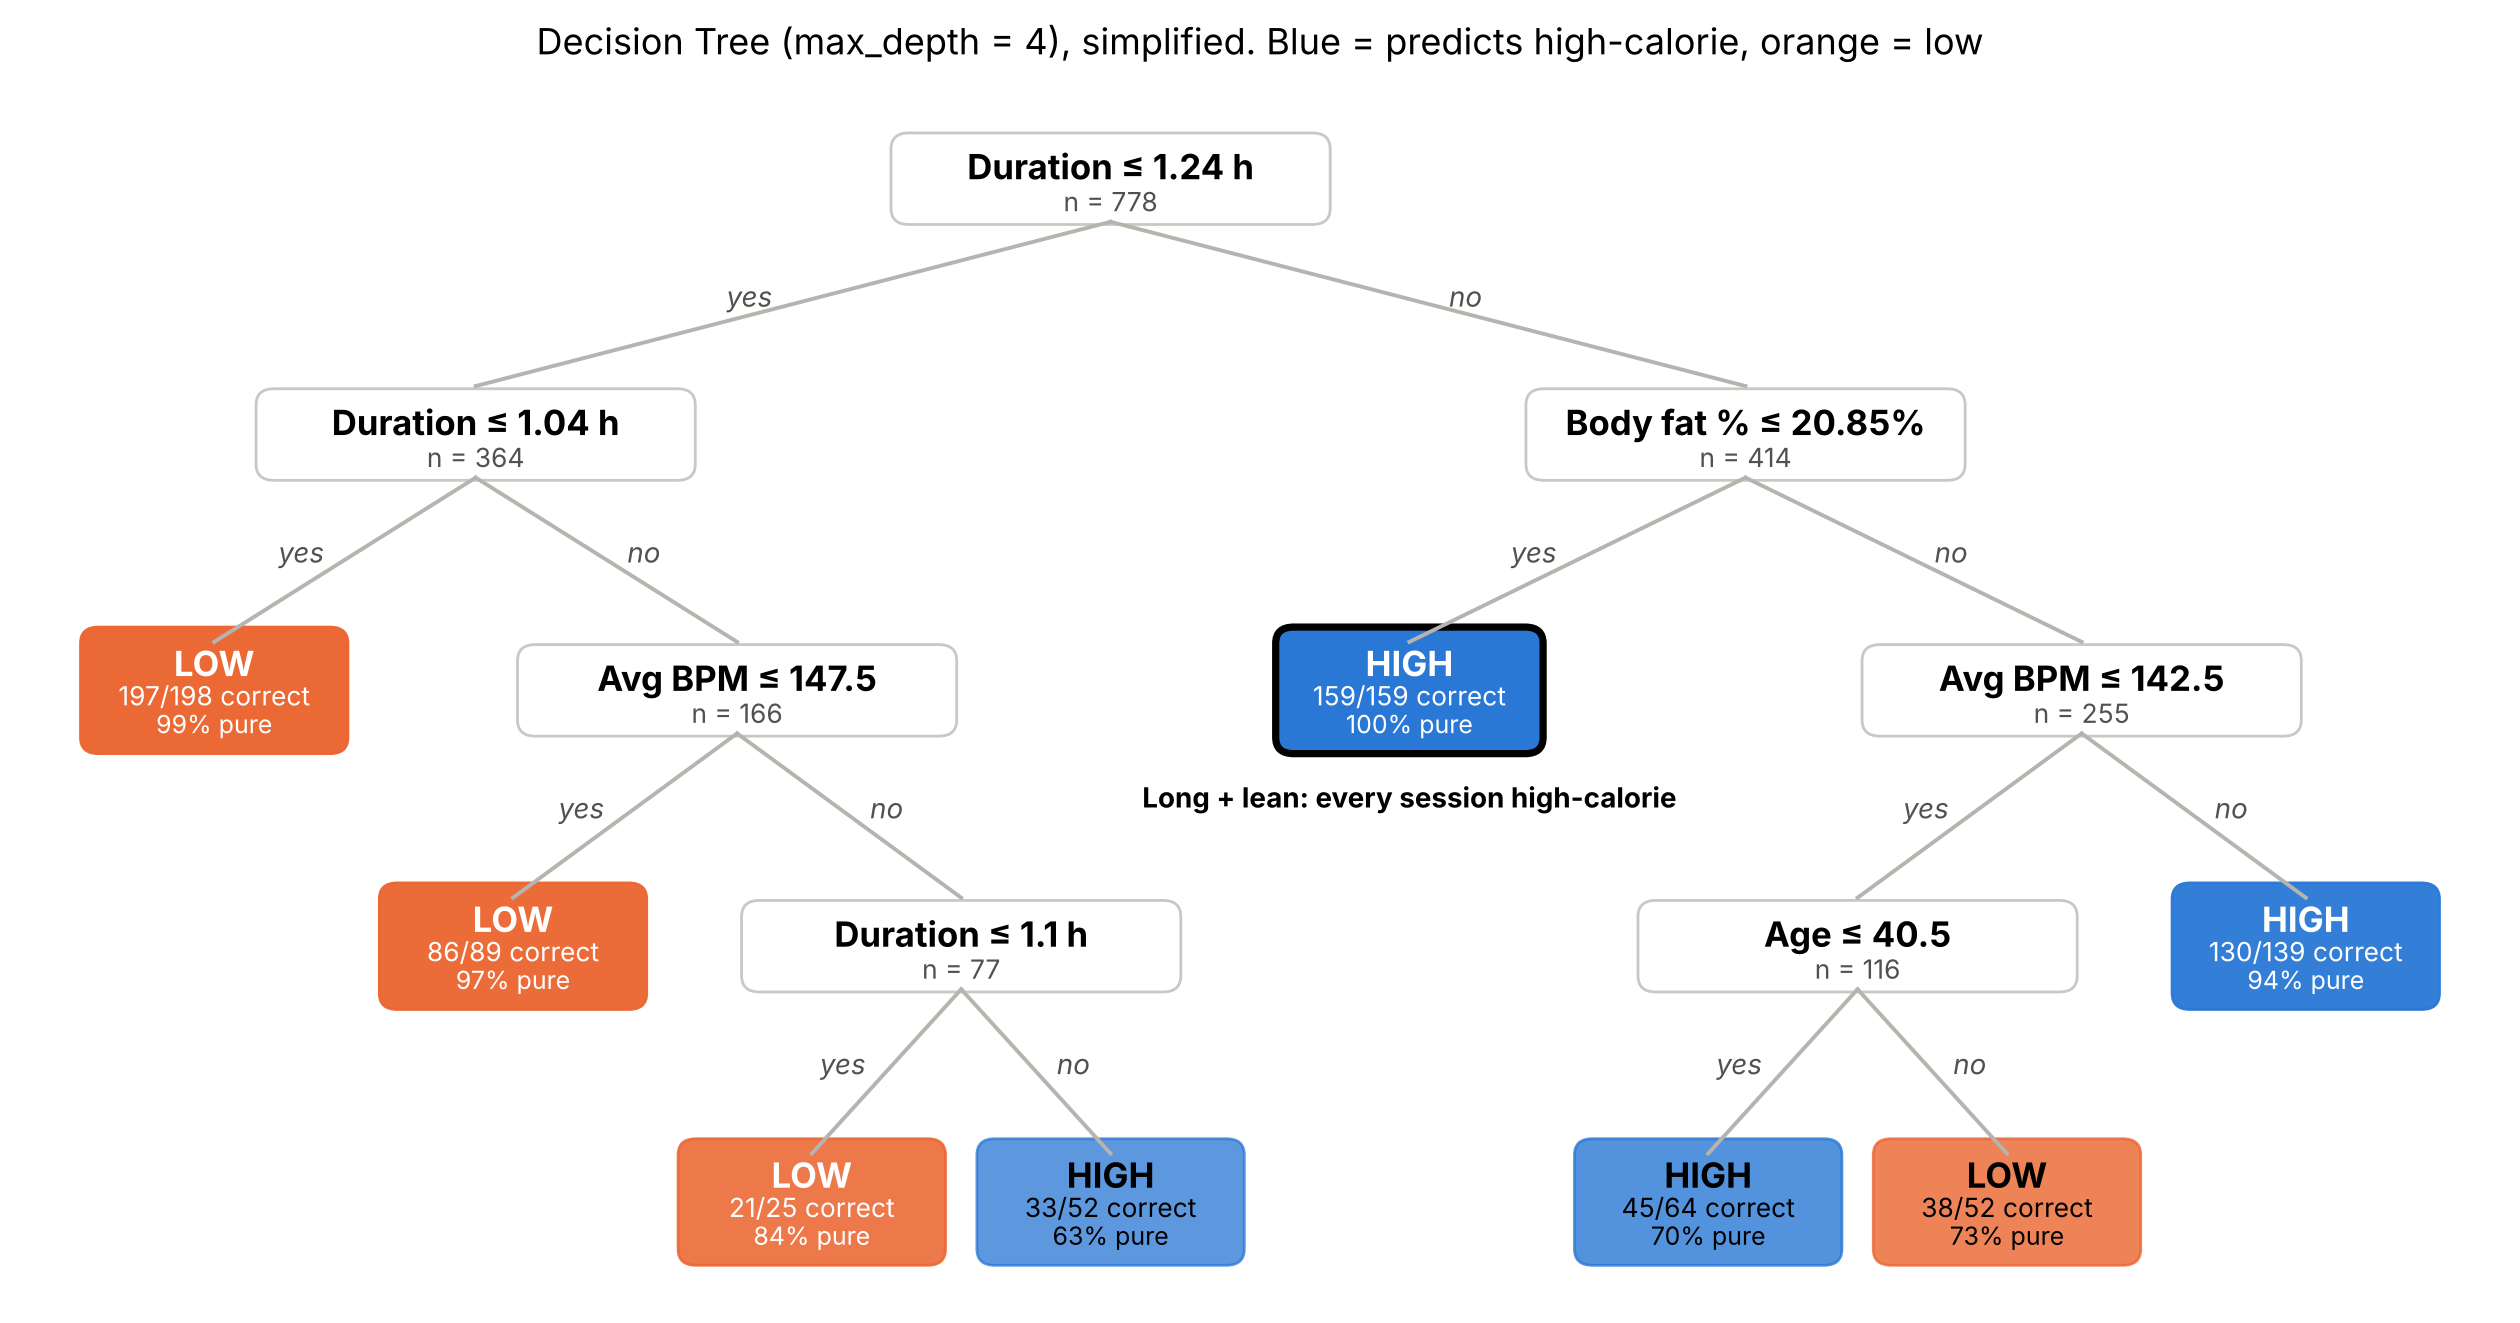

In [30]:
t = dt.tree_
cols = list(Xtr_dt.columns)
def collapse(n):
    cnt = (t.value[n][0] / t.value[n][0].sum() * t.n_node_samples[n]).round().astype(int)
    if t.children_left[n] == -1:
        return ('leaf', cnt)
    L, R = collapse(t.children_left[n]), collapse(t.children_right[n])
    if L[0] == 'leaf' and R[0] == 'leaf' and L[1].argmax() == R[1].argmax():
        return ('leaf', cnt)
    return ('split', cols[t.feature[n]], t.threshold[n], L, R, cnt)
T = collapse(0)

def predict_simple(node, row):
    while node[0] == 'split':
        node = node[3] if row[node[1]] <= node[2] else node[4]
    return node[1].argmax()
same = all(predict_simple(T, r) == p for (_, r), p in zip(Xte_dt.iterrows(), dt.predict(Xte_dt)))
print('Simplified tree gives identical test predictions:', same)

names = {'Session_Duration (hours)': 'Duration', 'Avg_BPM': 'Avg BPM', 'Fat_Percentage': 'Body fat %', 'Age': 'Age'}
units = {'Session_Duration (hours)': ' h', 'Fat_Percentage': '%'}
pos, order = {}, []
def lay(nd, depth, path):
    if nd[0] == 'leaf':
        pos[path] = (len(order), depth); order.append(path); return pos[path][0]
    a, b = lay(nd[3], depth+1, path+'L'), lay(nd[4], depth+1, path+'R')
    pos[path] = ((a+b)/2, depth); return pos[path][0]
lay(T, 0, '')
fig, ax = plt.subplots(figsize=(16, 8)); ax.axis('off')
P = lambda p: (pos[p][0]*2.0, pos[p][1]*-1.9)
def draw(nd, path):
    x, y0 = P(path)
    if nd[0] == 'split':
        for ch, lab in [('L', 'yes'), ('R', 'no')]:
            cx, cy = P(path+ch)
            ax.plot([x, cx], [y0-0.32, cy+0.36], color='#b5b4ae', lw=1.4)
            ax.text((x+cx)/2 + (-0.14 if ch == 'L' else 0.14), (y0+cy)/2, lab, ha='right' if ch == 'L' else 'left', style='italic', color='#52514e')
        ax.add_patch(FancyBboxPatch((x-1.45, y0-0.32), 2.9, 0.64, boxstyle='round,pad=0.02,rounding_size=0.12', fc='white', ec='#c9c8c2'))
        ax.text(x, y0+0.09, f"{names[nd[1]]} ≤ {round(nd[2], 2):g}{units.get(nd[1], '')}", ha='center', va='center', fontsize=12.5, fontweight='bold')
        ax.text(x, y0-0.17, f"n = {nd[5].sum()}", ha='center', va='center', fontsize=9.5, color='#52514e')
        draw(nd[3], path+'L'); draw(nd[4], path+'R')
    else:
        lo, hi = nd[1]; n = lo+hi; cls = int(hi > lo); pur = max(lo, hi)/n
        c = '#2a78d6' if cls else '#eb6834'; star = lo == 0 and hi > 100
        ax.add_patch(FancyBboxPatch((x-0.875, y0-0.45), 1.75, 0.9, boxstyle='round,pad=0.02,rounding_size=0.12',
                                    fc=c, ec='black' if star else c, lw=2.6 if star else 1, alpha=0.35+0.65*pur))
        tc = 'white' if pur > 0.8 else 'black'
        ax.text(x, y0+0.2, 'HIGH' if cls else 'LOW', ha='center', va='center', fontsize=12.5, fontweight='bold', color=tc)
        ax.text(x, y0-0.04, f"{max(lo, hi)}/{n} correct", ha='center', va='center', fontsize=9.5, color=tc)
        ax.text(x, y0-0.25, f"{pur*100:.0f}% pure", ha='center', va='center', fontsize=9, color=tc)
        if star: ax.text(x, y0-0.67, 'Long + lean: every session high-calorie', ha='center', va='top', fontsize=10, fontweight='bold')
draw(T, '')
xs = [P(p)[0] for p in pos]; ys = [P(p)[1] for p in pos]
ax.set_xlim(min(xs)-1.3, max(xs)+1.3); ax.set_ylim(min(ys)-0.75, max(ys)+0.8)
ax.set_title('Decision Tree (max_depth = 4), simplified. Blue = predicts high-calorie, orange = low', fontsize=13)
plt.show()

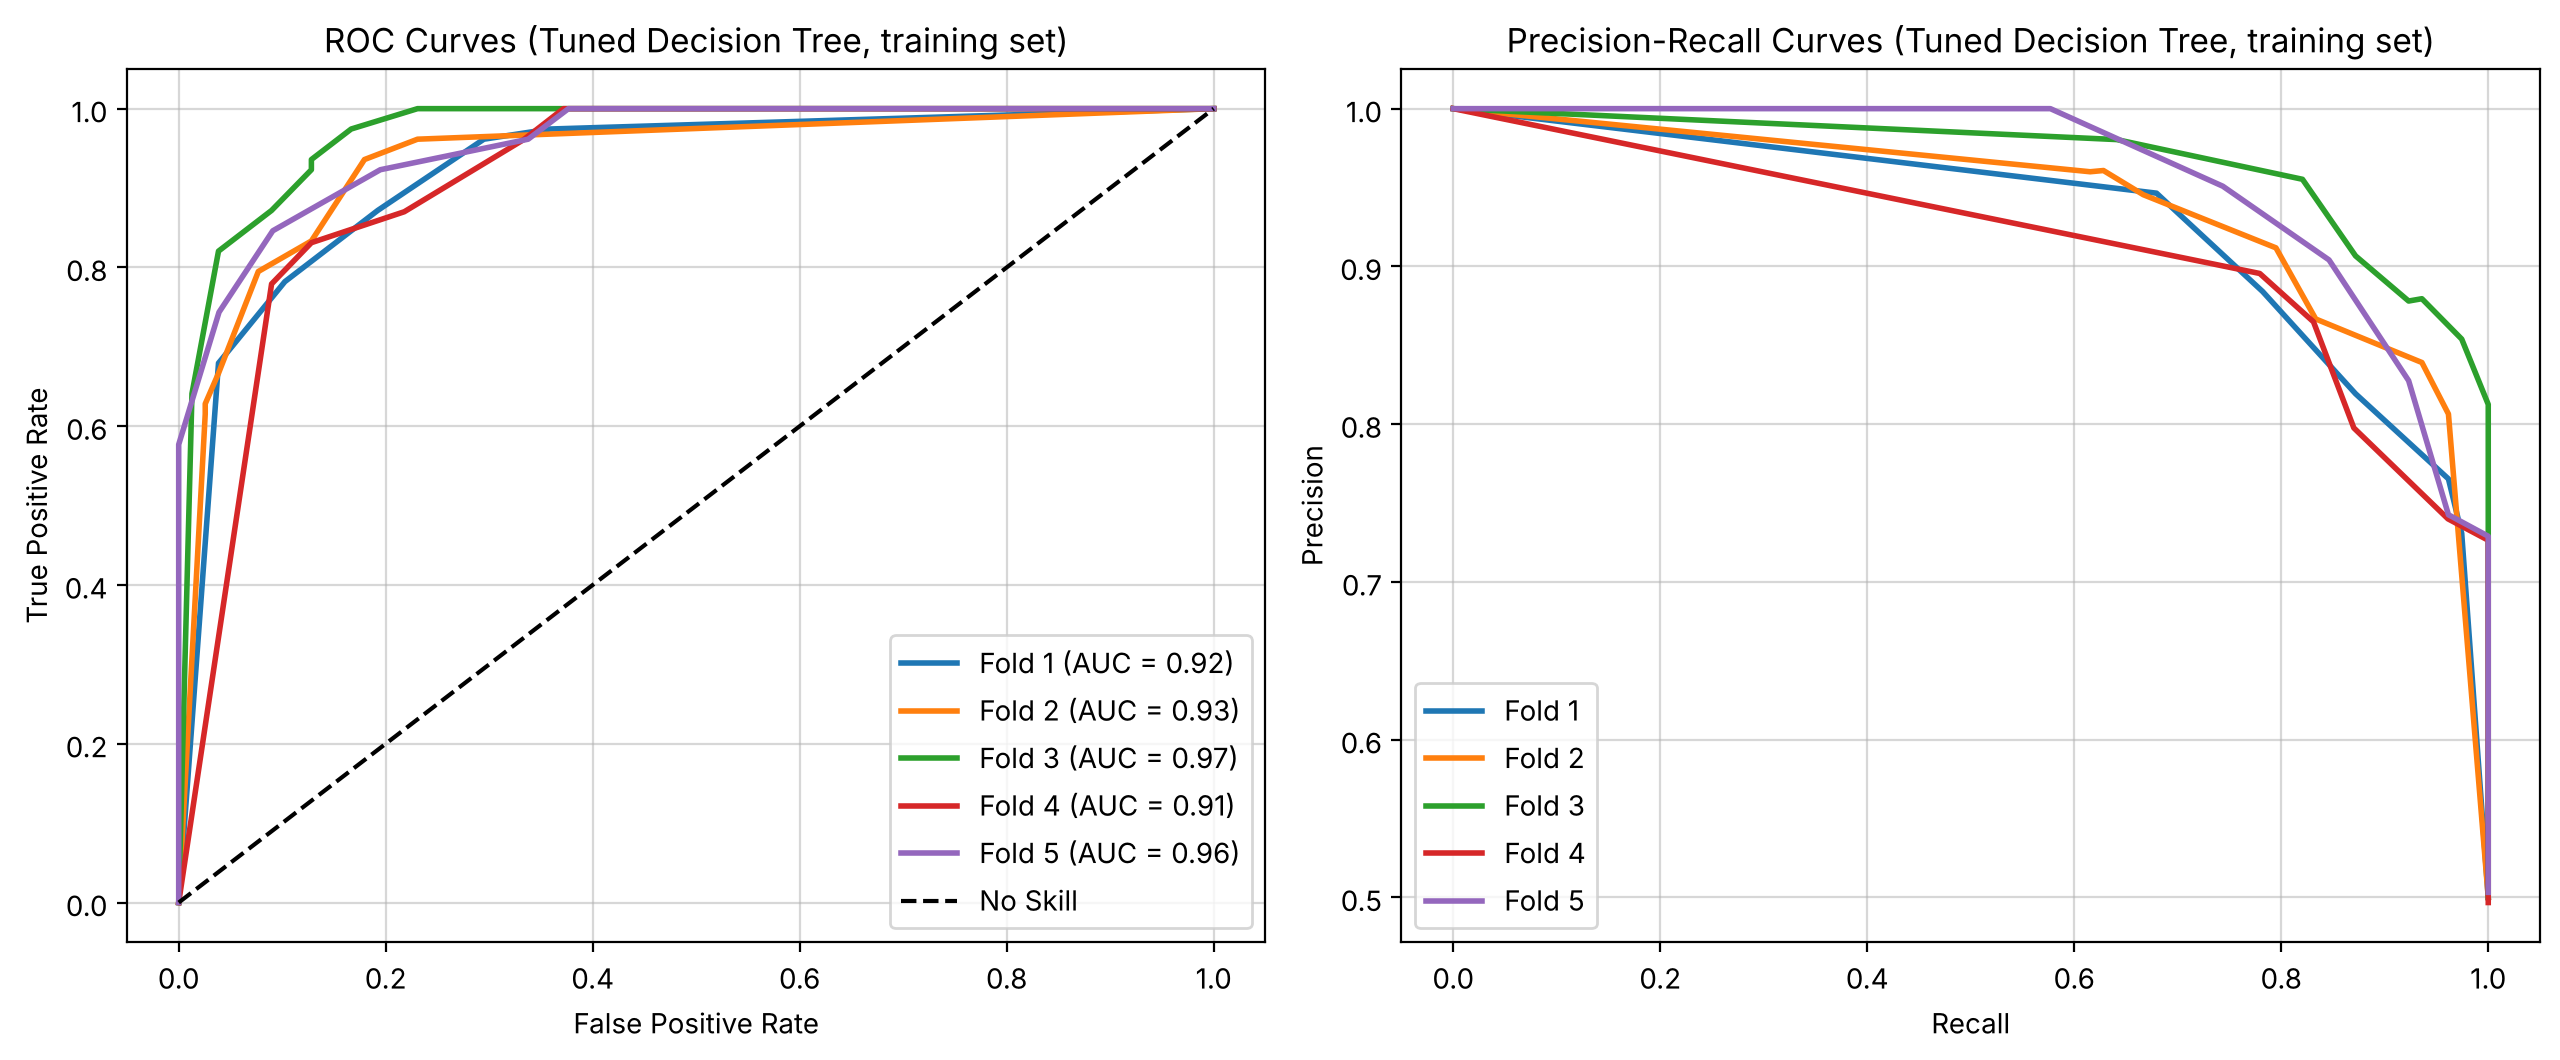

Avg accuracy 0.8625 | precision 0.8733 | recall 0.8508 | fold AUC 0.91-0.97


In [31]:
def fold_curves(title, X_tr, predict_fn):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.9, 5.4)); m = []
    for i, (tr, va) in enumerate(cv5.split(X_tr, y_train), 1):
        p = predict_fn(X_tr.iloc[tr], y_train.iloc[tr], X_tr.iloc[va]); yt = y_train.iloc[va]
        f, tp, _ = roc_curve(yt, p); a1.plot(f, tp, lw=2, label=f'Fold {i} (AUC = {auc(f, tp):.2f})')
        pr, rc, _ = precision_recall_curve(yt, p); a2.plot(rc, pr, lw=2, label=f'Fold {i}')
        h = (p > 0.5).astype(int)
        m.append((accuracy_score(yt, h), precision_score(yt, h), recall_score(yt, h), auc(f, tp)))
    a1.plot([0, 1], [0, 1], 'k--', label='No Skill')
    a1.set(title=f'ROC Curves ({title})', xlabel='False Positive Rate', ylabel='True Positive Rate'); a1.legend(loc='lower right'); a1.grid(alpha=.5)
    a2.set(title=f'Precision-Recall Curves ({title})', xlabel='Recall', ylabel='Precision'); a2.legend(loc='lower left'); a2.grid(alpha=.5)
    plt.tight_layout(); plt.show()
    m = np.array(m)
    print(f'Avg accuracy {m[:,0].mean():.4f} | precision {m[:,1].mean():.4f} | recall {m[:,2].mean():.4f} | fold AUC {m[:,3].min():.2f}-{m[:,3].max():.2f}')

fold_curves('Tuned Decision Tree, training set', Xtr_dt,
            lambda a, b, c: DecisionTreeClassifier(max_depth=4, **dt_params).fit(a, b).predict_proba(c)[:, 1])

## 3.2 k-Nearest Neighbors (slides 5–7)
The scaler is always fit on training data only.

In [32]:
X_knn = pd.get_dummies(X, columns=['Gender', 'Workout_Type'], drop_first=True).astype(float)   # 16 features
Xtr_k, Xte_k = X_knn.loc[X_train.index], X_knn.loc[X_test.index]

corr = data.select_dtypes('number').corr()['Calories_Burned'].drop('Calories_Burned').abs().sort_values(ascending=False)
display(corr.round(3).to_frame('|r| with calories'))
top4 = ['Session_Duration (hours)', 'Avg_BPM', 'Fat_Percentage', 'Experience_Level']
by_corr = list(corr.index[:4])
cmp_ = {}
for name, feats in [('Selected 4 (with Avg_BPM)', top4), ('Top 4 by |r| (with Workout_Frequency)', by_corr)]:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9, weights='distance'))
    cmp_[name] = cross_val_score(pipe, X_train[feats], y_train, cv=cv5).mean()
display(pd.Series(cmp_, name='5-fold CV accuracy').round(4).to_frame())
print('Feature set used:', top4)
print('Avg_BPM is only 6th by correlation, but it beats Workout_Frequency in CV, so the selected 4 are the 3 strongest correlates plus Avg_BPM.')

,|r| with calories
Session_Duration (hours),0.908
Experience_Level,0.694
Fat_Percentage,0.598
Workout_Frequency (days/week),0.576
Water_Intake (liters),0.357
Avg_BPM,0.340
Age,0.155
Weight (lb),0.095
Height (in),0.086
BMI,0.060


,5-fold CV accuracy
Selected 4 (with Avg_BPM),0.9152
Top 4 by |r| (with Workout_Frequency),0.8419


Feature set used: ['Session_Duration (hours)', 'Avg_BPM', 'Fat_Percentage', 'Experience_Level']
Avg_BPM is only 6th by correlation, but it beats Workout_Frequency in CV, so the selected 4 are the 3 strongest correlates plus Avg_BPM.


In [33]:
# Model selection by 5-fold CV on the training set only
rows = []
for feats_name, feats in [('all 16', list(Xtr_k.columns)), ('top 4', top4)]:
    for w in ['uniform', 'distance']:
        for k in range(1, 26, 2):
            pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k, weights=w))
            rows.append({'features': feats_name, 'weights': w, 'k': k,
                         'cv_acc': cross_val_score(pipe, Xtr_k[feats], y_train, cv=cv5).mean()})
knn_cv = pd.DataFrame(rows)
best = knn_cv.loc[knn_cv.cv_acc.idxmax()]
display(knn_cv.sort_values('cv_acc', ascending=False).head(8).round(4))
print('Selected by CV:', best.to_dict())

,features,weights,k,cv_acc
43,top 4,distance,9,0.9152
46,top 4,distance,15,0.9126
44,top 4,distance,11,0.9113
48,top 4,distance,19,0.9100
51,top 4,distance,25,0.9100
47,top 4,distance,17,0.9087
30,top 4,uniform,9,0.9074
49,top 4,distance,21,0.9074


Selected by CV: {'features': 'top 4', 'weights': 'distance', 'k': 9, 'cv_acc': 0.9151778329197683}


In [34]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9, weights='distance')).fit(Xtr_k[top4], y_train)
print(f'Final k-NN (k=9, distance, top 4): CV {knn_cv.query("features==\'top 4\' and weights==\'distance\' and k==9").cv_acc.iloc[0]:.4f} | test {knn.score(Xte_k[top4], y_test):.4f}')

# For reference only: the test score at k=17 is higher, but choosing k from the test set would be tuning on it
k17 = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=17, weights='distance')).fit(Xtr_k[top4], y_train)
print(f'(k=17 test accuracy: {k17.score(Xte_k[top4], y_test):.4f}, not used: picking k by test score is leakage)')

Final k-NN (k=9, distance, top 4): CV 0.9152 | test 0.9282
(k=17 test accuracy: 0.9641, not used: picking k by test score is leakage)


### Optimization steps (slide 7) and bias–variance chart (slide 6)
These use holdout test accuracy to *illustrate* each step; the final settings above came from CV.

1. Unscaled, all features, k=5      72.82%
2. Scaled, all features, k=5        82.56%
3. Scaled, k=9, uniform             88.21%
4. k=9 + distance + top 4           92.82%


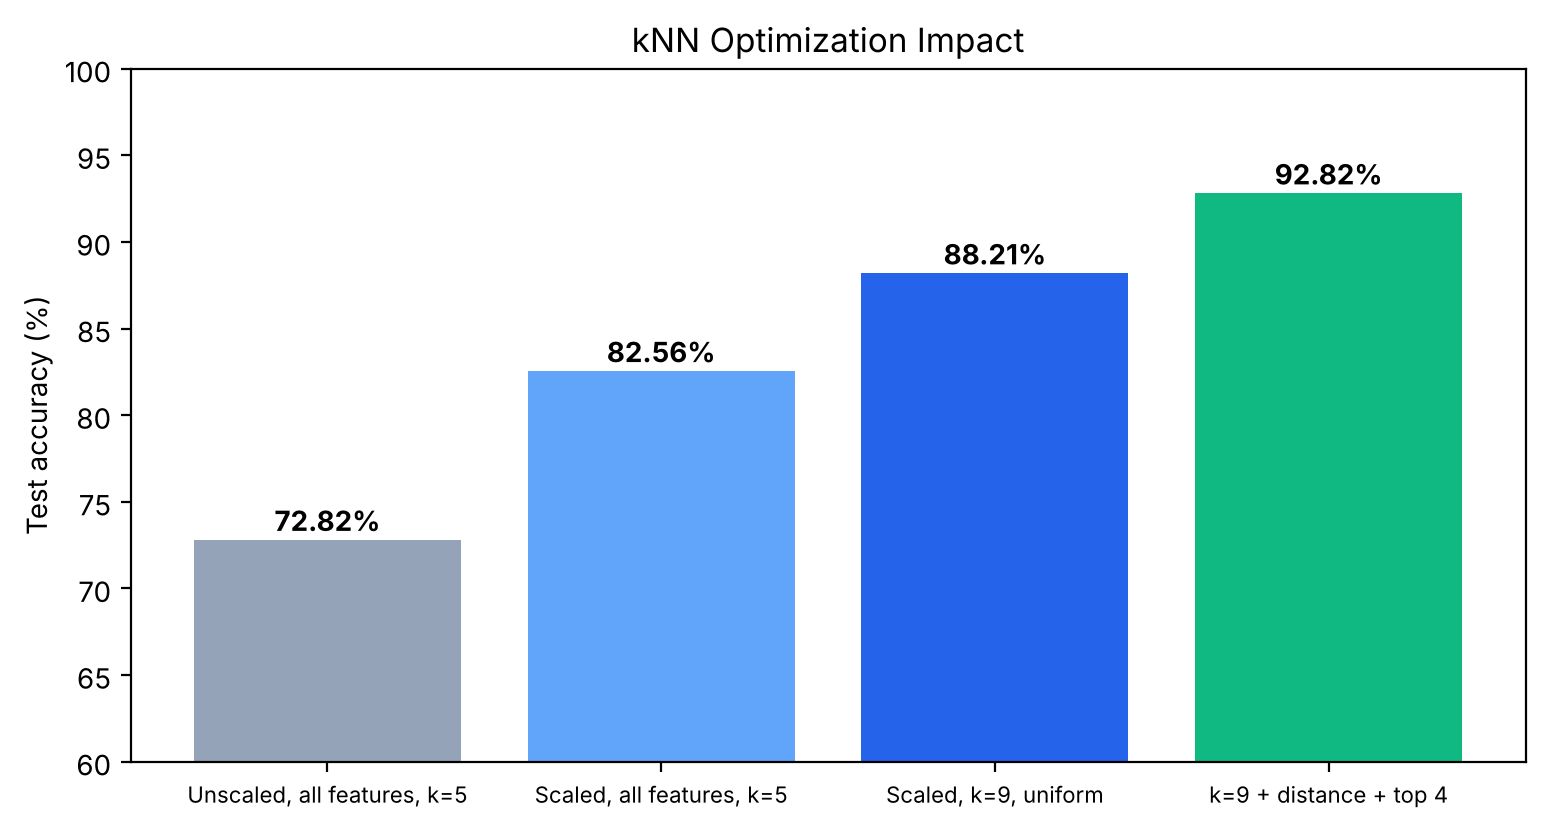

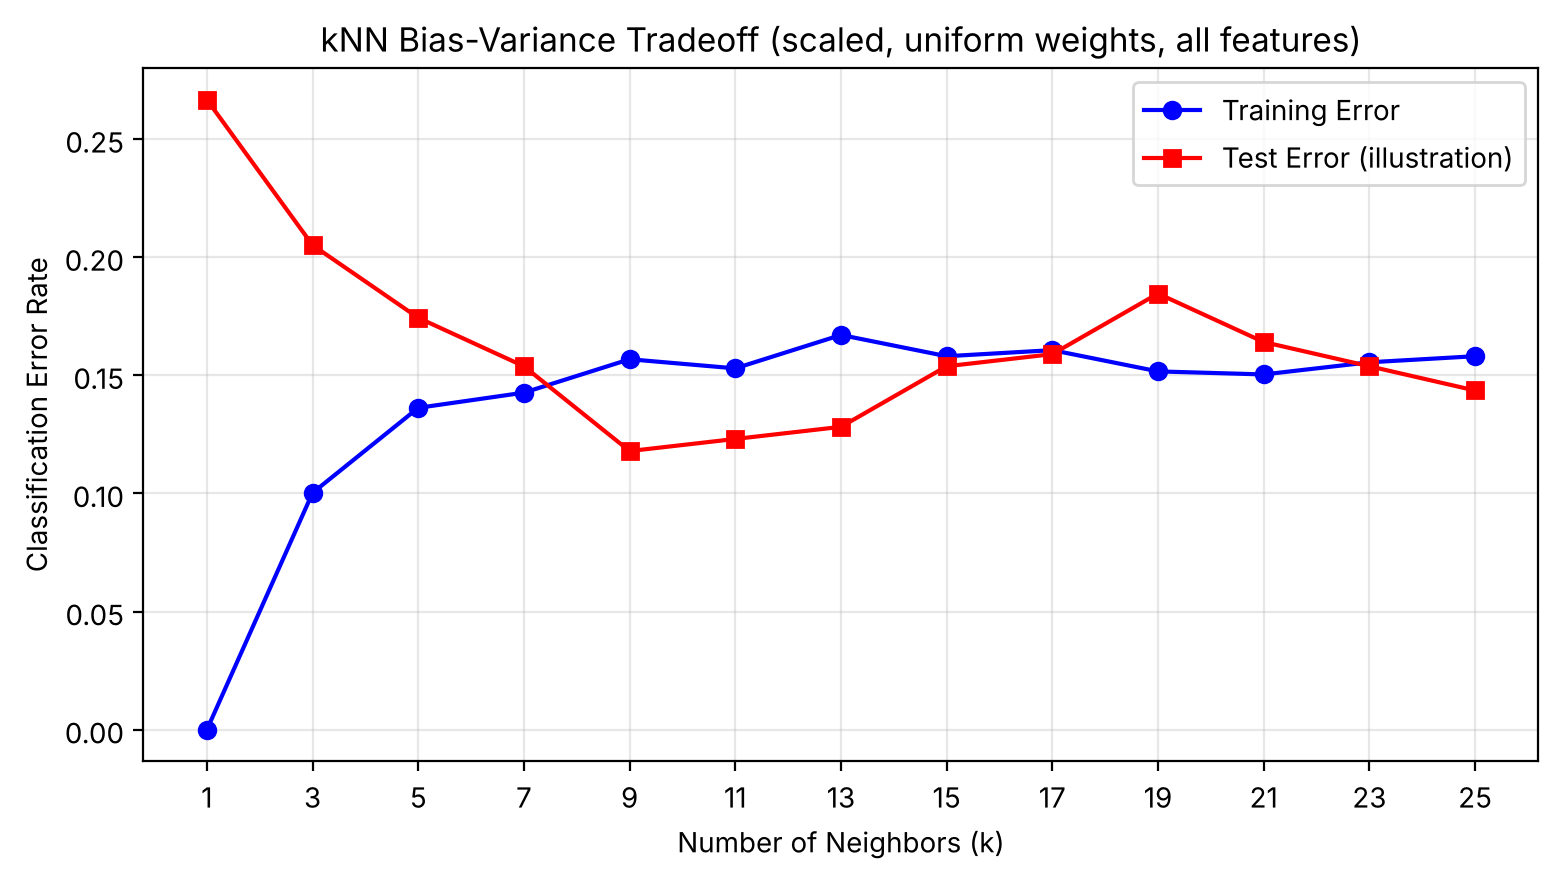

k=1: train error 0.00, test error 26.7% | k=9 test accuracy 88.21%


In [35]:
steps = {}
steps['1. Unscaled, all features, k=5'] = KNeighborsClassifier(5).fit(Xtr_k, y_train).score(Xte_k, y_test)
sc = StandardScaler().fit(Xtr_k); A, B = sc.transform(Xtr_k), sc.transform(Xte_k)
steps['2. Scaled, all features, k=5'] = KNeighborsClassifier(5).fit(A, y_train).score(B, y_test)
steps['3. Scaled, k=9, uniform'] = KNeighborsClassifier(9).fit(A, y_train).score(B, y_test)
steps['4. k=9 + distance + top 4'] = knn.score(Xte_k[top4], y_test)
for s, v in steps.items(): print(f'{s:35s} {v*100:.2f}%')
plt.figure(figsize=(9, 4.5))
bars = plt.bar(range(4), [v*100 for v in steps.values()], color=['#94a3b8', '#60a5fa', '#2563eb', '#10b981'])
for b, v in zip(bars, steps.values()): plt.text(b.get_x()+b.get_width()/2, v*100+0.5, f'{v*100:.2f}%', ha='center', fontweight='bold')
plt.xticks(range(4), [s.split('. ')[1] for s in steps], fontsize=8); plt.ylim(60, 100); plt.ylabel('Test accuracy (%)')
plt.title('kNN Optimization Impact'); plt.show()

ks = list(range(1, 26, 2)); tr_err, te_err = [], []
for k in ks:
    m = KNeighborsClassifier(k).fit(A, y_train)
    tr_err.append(1 - m.score(A, y_train)); te_err.append(1 - m.score(B, y_test))
plt.figure(figsize=(9, 4.5))
plt.plot(ks, tr_err, 'o-', color='blue', label='Training Error'); plt.plot(ks, te_err, 's-', color='red', label='Test Error (illustration)')
plt.xticks(ks); plt.xlabel('Number of Neighbors (k)'); plt.ylabel('Classification Error Rate')
plt.title('kNN Bias-Variance Tradeoff (scaled, uniform weights, all features)'); plt.legend(); plt.grid(alpha=.3); plt.show()
print(f'k=1: train error {tr_err[0]:.2f}, test error {te_err[0]*100:.1f}% | k=9 test accuracy {(1-te_err[4])*100:.2f}%')

## 3.3 Naïve Bayes (slides 8–10)
GaussianNB on 11 continuous features + CategoricalNB on 3 discrete ones. Their joint log-likelihoods are added, one copy of the class prior is subtracted (it is counted twice), then normalized.

11 continuous: ['Age', 'Max_BPM', 'Avg_BPM', 'Resting_BPM', 'Session_Duration (hours)', 'Fat_Percentage', 'Water_Intake (liters)', 'Workout_Frequency (days/week)', 'BMI', 'Weight (lb)', 'Height (in)']


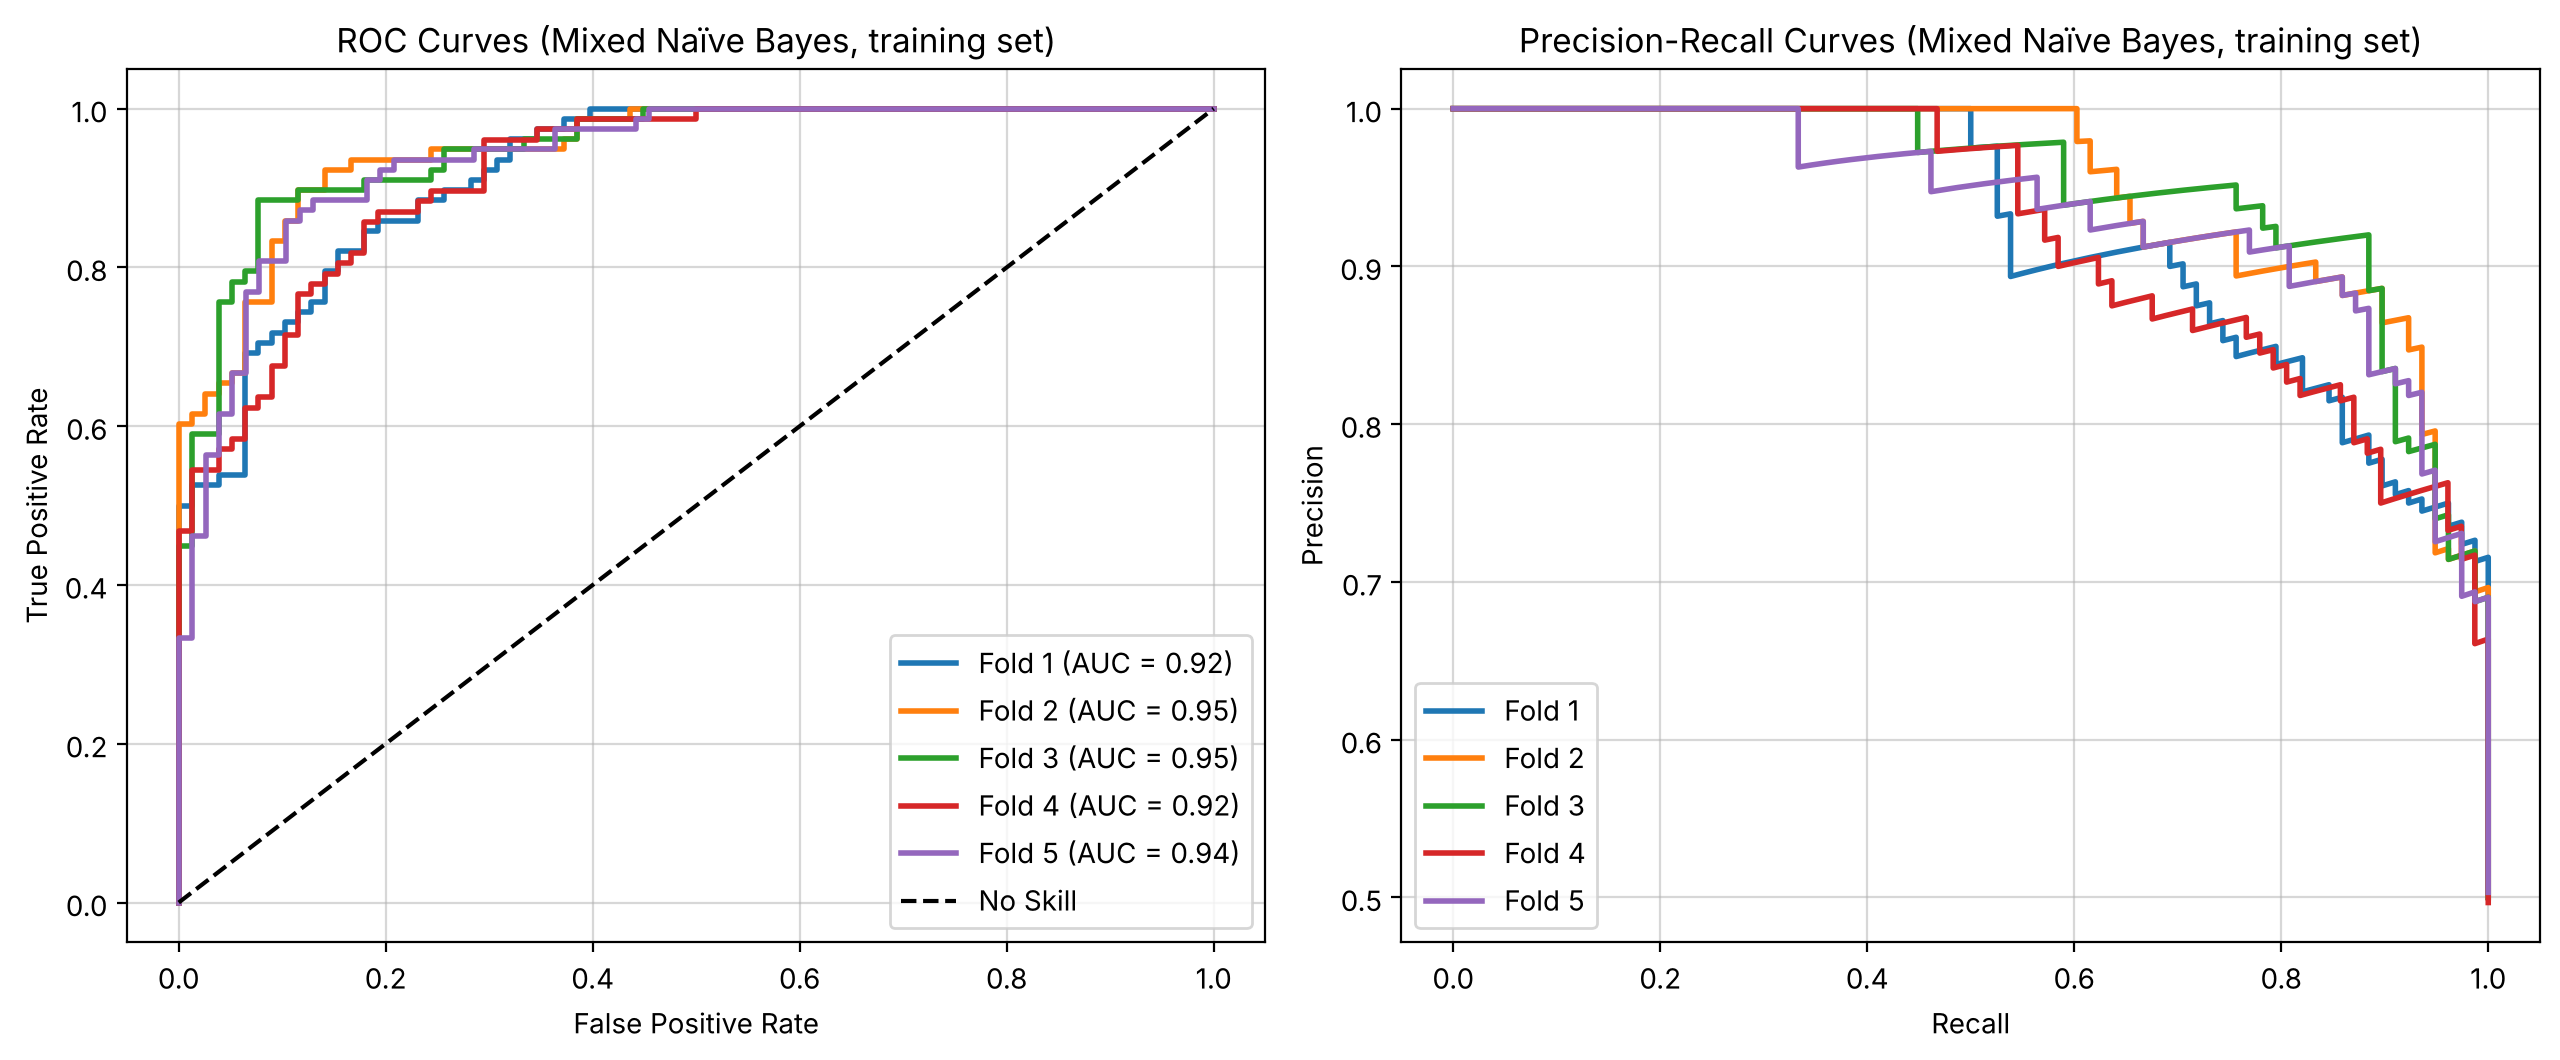

Avg accuracy 0.8136 | precision 0.9017 | recall 0.7070 | fold AUC 0.92-0.95


In [36]:
cat_cols = ['Gender', 'Workout_Type', 'Experience_Level']
num_cols = [c for c in X.columns if c not in cat_cols]
print(len(num_cols), 'continuous:', num_cols)

def mixed_nb_proba(X_a, y_a, X_b):
    g = GaussianNB().fit(X_a[num_cols], y_a)
    oe = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1).fit(X_a[cat_cols])
    c = CategoricalNB(alpha=1.0).fit(oe.transform(X_a[cat_cols]).astype(int), y_a)
    jll = (g.predict_joint_log_proba(X_b[num_cols]) + c.predict_joint_log_proba(oe.transform(X_b[cat_cols]).astype(int))
           - np.log(g.class_prior_))
    return np.exp(jll - logsumexp(jll, axis=1, keepdims=True))[:, 1]

fold_curves('Mixed Naïve Bayes, training set', X_train, mixed_nb_proba)

{'Model': 'Mixed Naïve Bayes', 'Accuracy': 0.8205, 'Precision': 0.878, 'Recall': 0.7423, 'F1': 0.8045, 'ROC AUC': 0.942}


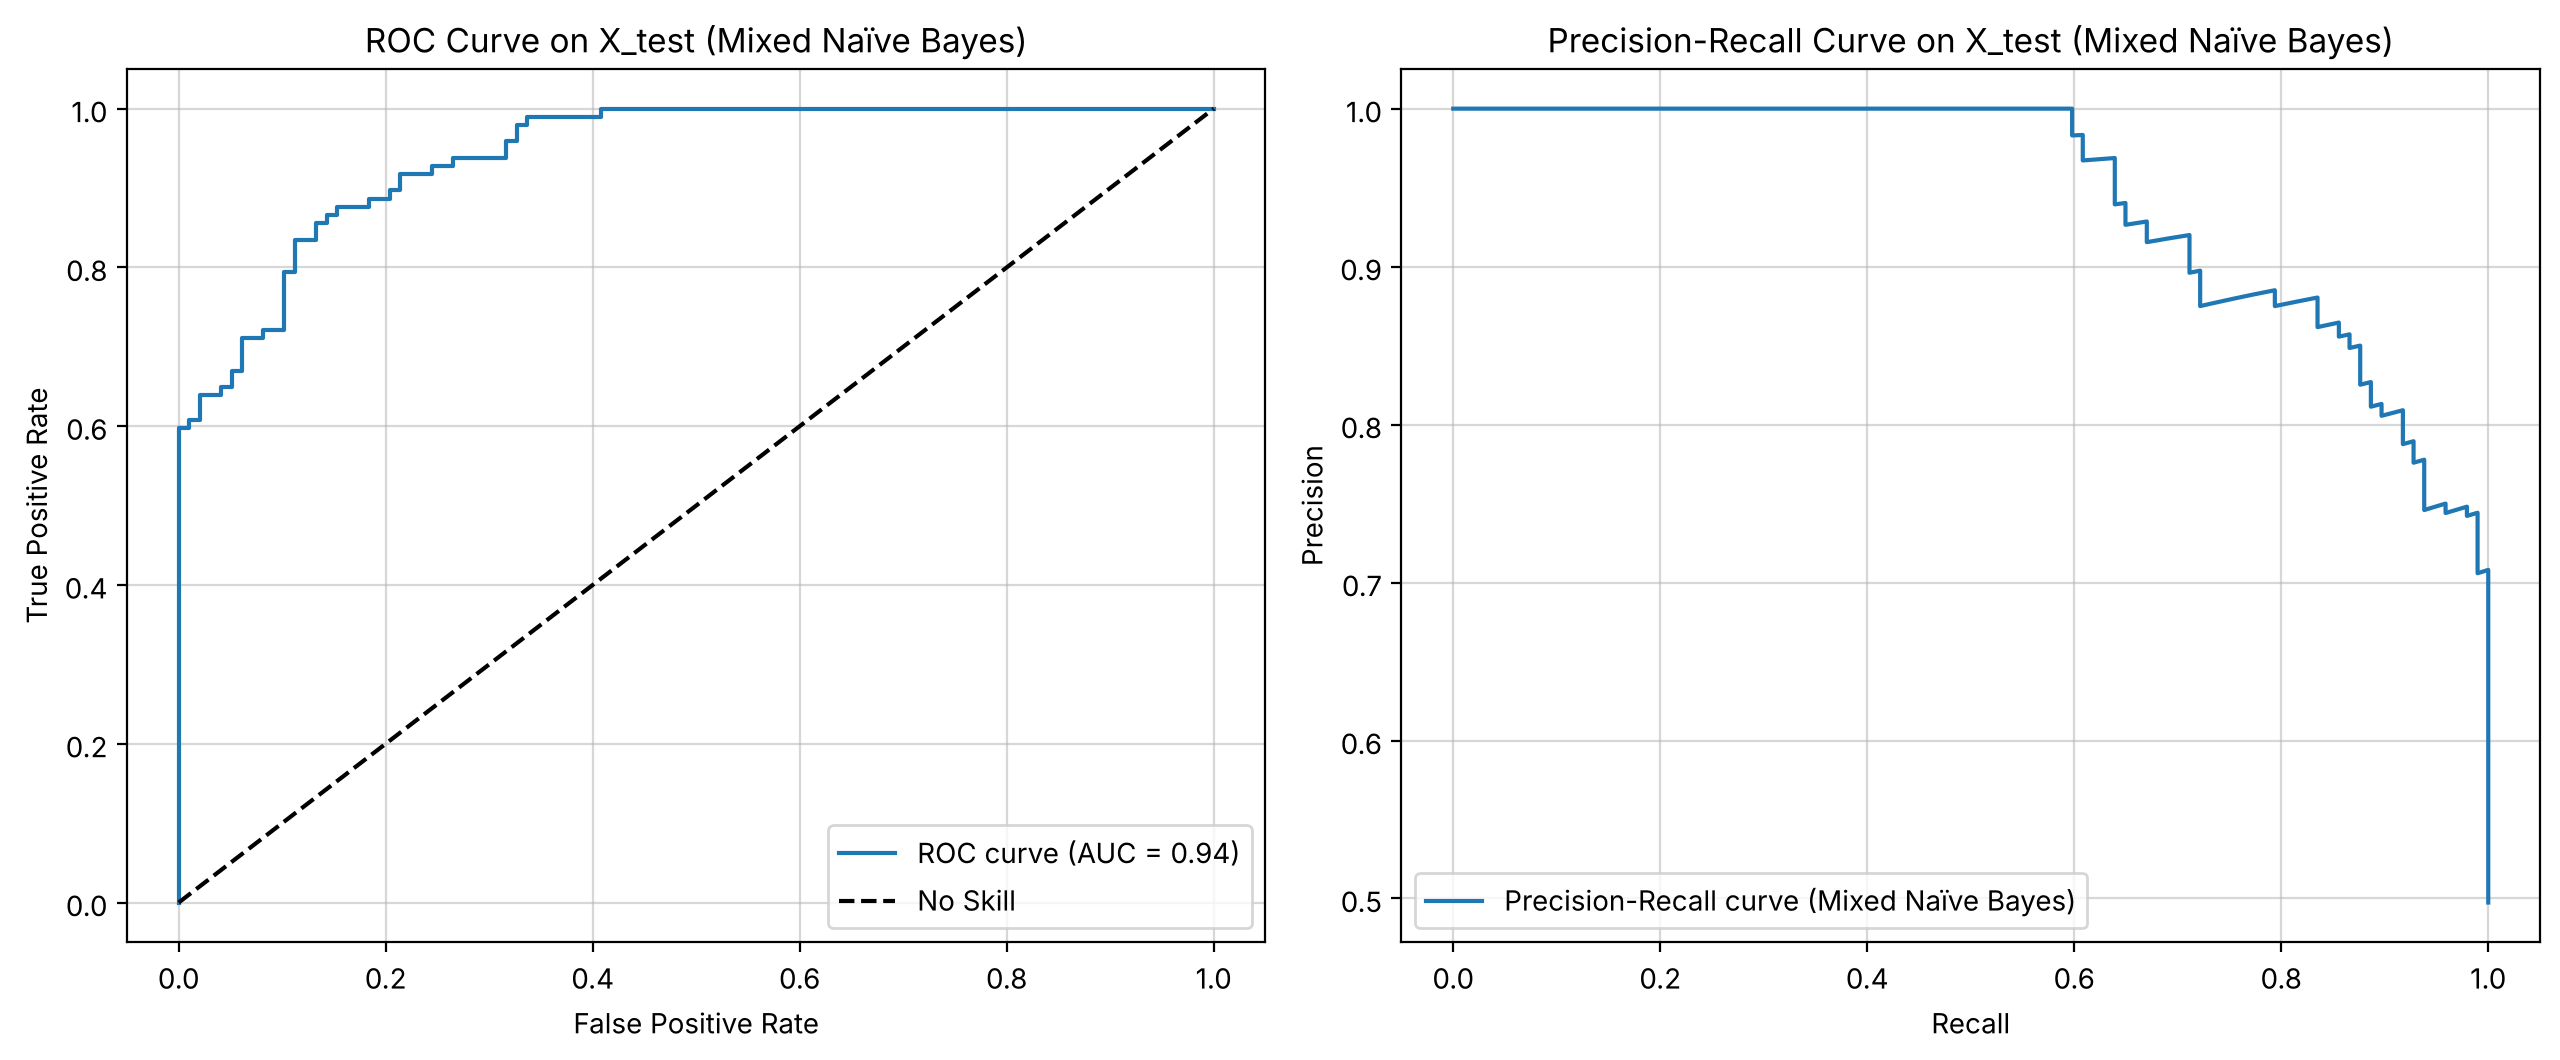

In [37]:
p_nb = mixed_nb_proba(X_train, y_train, X_test)
nb_res = report('Mixed Naïve Bayes', y_test, (p_nb >= 0.5).astype(int), p_nb)
print({k: round(v, 4) if isinstance(v, float) else v for k, v in nb_res.items()})

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.9, 5.4))
f, tp, _ = roc_curve(y_test, p_nb); a1.plot(f, tp, label=f'ROC curve (AUC = {auc(f, tp):.2f})'); a1.plot([0, 1], [0, 1], 'k--', label='No Skill')
a1.set(title='ROC Curve on X_test (Mixed Naïve Bayes)', xlabel='False Positive Rate', ylabel='True Positive Rate'); a1.legend(loc='lower right'); a1.grid(alpha=.5)
pr, rc, _ = precision_recall_curve(y_test, p_nb); a2.plot(rc, pr, label='Precision-Recall curve (Mixed Naïve Bayes)')
a2.set(title='Precision-Recall Curve on X_test (Mixed Naïve Bayes)', xlabel='Recall', ylabel='Precision'); a2.legend(loc='lower left'); a2.grid(alpha=.5)
plt.tight_layout(); plt.show()

In [38]:
# Baseline comparison (slide 8): continuous-only GaussianNB
g_cv = cross_val_score(GaussianNB(), X_train[num_cols], y_train, cv=cv5).mean()
mixed_cv = np.mean([accuracy_score(y_train.iloc[va], (mixed_nb_proba(X_train.iloc[tr], y_train.iloc[tr], X_train.iloc[va]) >= 0.5).astype(int))
                    for tr, va in cv5.split(X_train, y_train)])
g_test = GaussianNB().fit(X_train[num_cols], y_train).score(X_test[num_cols], y_test)
display(pd.DataFrame({'5-fold CV (train)': [mixed_cv, g_cv], 'Test': [nb_res['Accuracy'], g_test]},
                     index=['Mixed NB', 'Gaussian-only NB']).round(4))
print('Finding: the simpler Gaussian-only model scores higher; the categorical attributes add noise rather than signal.')

,5-fold CV (train),Test
Mixed NB,0.8136,0.8205
Gaussian-only NB,0.8406,0.8513


Finding: the simpler Gaussian-only model scores higher; the categorical attributes add noise rather than signal.


## 3.4 Rule-Based Classification: FOIL (slides 11–12)

In [39]:
D, BPM = 'Session_Duration (hours)', 'Avg_BPM'
p0, n0 = int(y_train.sum()), int((1 - y_train).sum())
print(f'Base rule: p0 = {p0}, n0 = {n0}')

def foil_gain(cond):
    p1, n1 = int((cond & (y_train == 1)).sum()), int((cond & (y_train == 0)).sum())
    gain = p1 * (np.log2(p1 / (p1 + n1)) - np.log2(p0 / (p0 + n0))) if p1 else 0
    return p1, n1, gain

cands = {'Session_Duration > 1.25': X_train[D] > 1.25,
         'Experience_Level == 3': X_train['Experience_Level'] == 3,
         'Fat_Percentage <= 22': X_train['Fat_Percentage'] <= 22,
         'Avg_BPM > 145': X_train[BPM] > 145,
         'Age <= 35': X_train['Age'] <= 35}
rows = [{'condition': k, 'p1': (r := foil_gain(v))[0], 'n1': r[1], 'precision': r[0] / (r[0] + r[1]), 'FOIL gain': r[2]} for k, v in cands.items()]
display(pd.DataFrame(rows).sort_values('FOIL gain', ascending=False).round(2))

# Candidate rules: coverage and accuracy (slide 12)
cand_rules = [('R1 broad: Duration > 1.25 -> Yes', X_train[D] > 1.25, 1),
              ('R2 specialized: Duration > 1.15 & Avg_BPM > 145 -> Yes', (X_train[D] > 1.15) & (X_train[BPM] > 145), 1),
              ('R3 low-burn: Duration <= 1.10 -> No', X_train[D] <= 1.10, 0)]
for name, cond, cls in cand_rules:
    print(f'{name:55s} coverage {cond.mean()*100:.2f}% ({cond.sum()}/{len(cond)})  accuracy {(y_train[cond] == cls).mean()*100:.2f}%')
print('All expert sessions longer than 1.30 h:', (X_train.loc[X_train['Experience_Level'] == 3, D] > 1.30).all())

Base rule: p0 = 389, n0 = 389


,condition,p1,n1,precision,FOIL gain
0,Session_Duration > 1.25,337,59,0.85,258.56
1,Experience_Level == 3,152,0,1.00,152.00
2,Fat_Percentage <= 22,186,34,0.85,140.95
3,Avg_BPM > 145,223,137,0.62,68.92
4,Age <= 35,184,137,0.57,36.27


R1 broad: Duration > 1.25 -> Yes                        coverage 50.90% (396/778)  accuracy 85.10%
R2 specialized: Duration > 1.15 & Avg_BPM > 145 -> Yes  coverage 28.66% (223/778)  accuracy 92.38%
R3 low-burn: Duration <= 1.10 -> No                     coverage 32.39% (252/778)  accuracy 96.03%
All expert sessions longer than 1.30 h: True


In [40]:
# Final ordered decision list (slide 11)
def rule_list(df):
    r1 = df[D] > 1.30
    r2 = ~r1 & (df[D] > 1.15) & (df[BPM] > 142)
    return r1, r2

r1, r2 = rule_list(X_train)
conf = {'r1': y_train[r1].mean(), 'r2': y_train[r2].mean(), 'default': y_train[~(r1 | r2)].mean()}  # used as scores for the ROC curve
r1t, r2t = rule_list(X_test)
pred_rules = (r1t | r2t).astype(int)
score_rules = np.where(r1t, conf['r1'], np.where(r2t, conf['r2'], conf['default']))
rules_res = report('FOIL Ordered Rules', y_test, pred_rules, score_rules)
print({k: round(v, 4) if isinstance(v, float) else v for k, v in rules_res.items()})

{'Model': 'FOIL Ordered Rules', 'Accuracy': 0.9077, 'Precision': 0.8911, 'Recall': 0.9278, 'F1': 0.9091, 'ROC AUC': 0.9162}


## 3.5 Model comparison on the holdout test set (slides 13–14)

,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Decision Tree (max_depth=4),93.3,92.0,94.8,93.4,0.988
"Tuned kNN (Top 4, k=9)",92.8,95.6,89.7,92.6,0.989
FOIL Ordered Rules,90.8,89.1,92.8,90.9,0.916
Mixed Naïve Bayes,82.1,87.8,74.2,80.4,0.942


Decision Tree vs k-NN: 1 test session apart


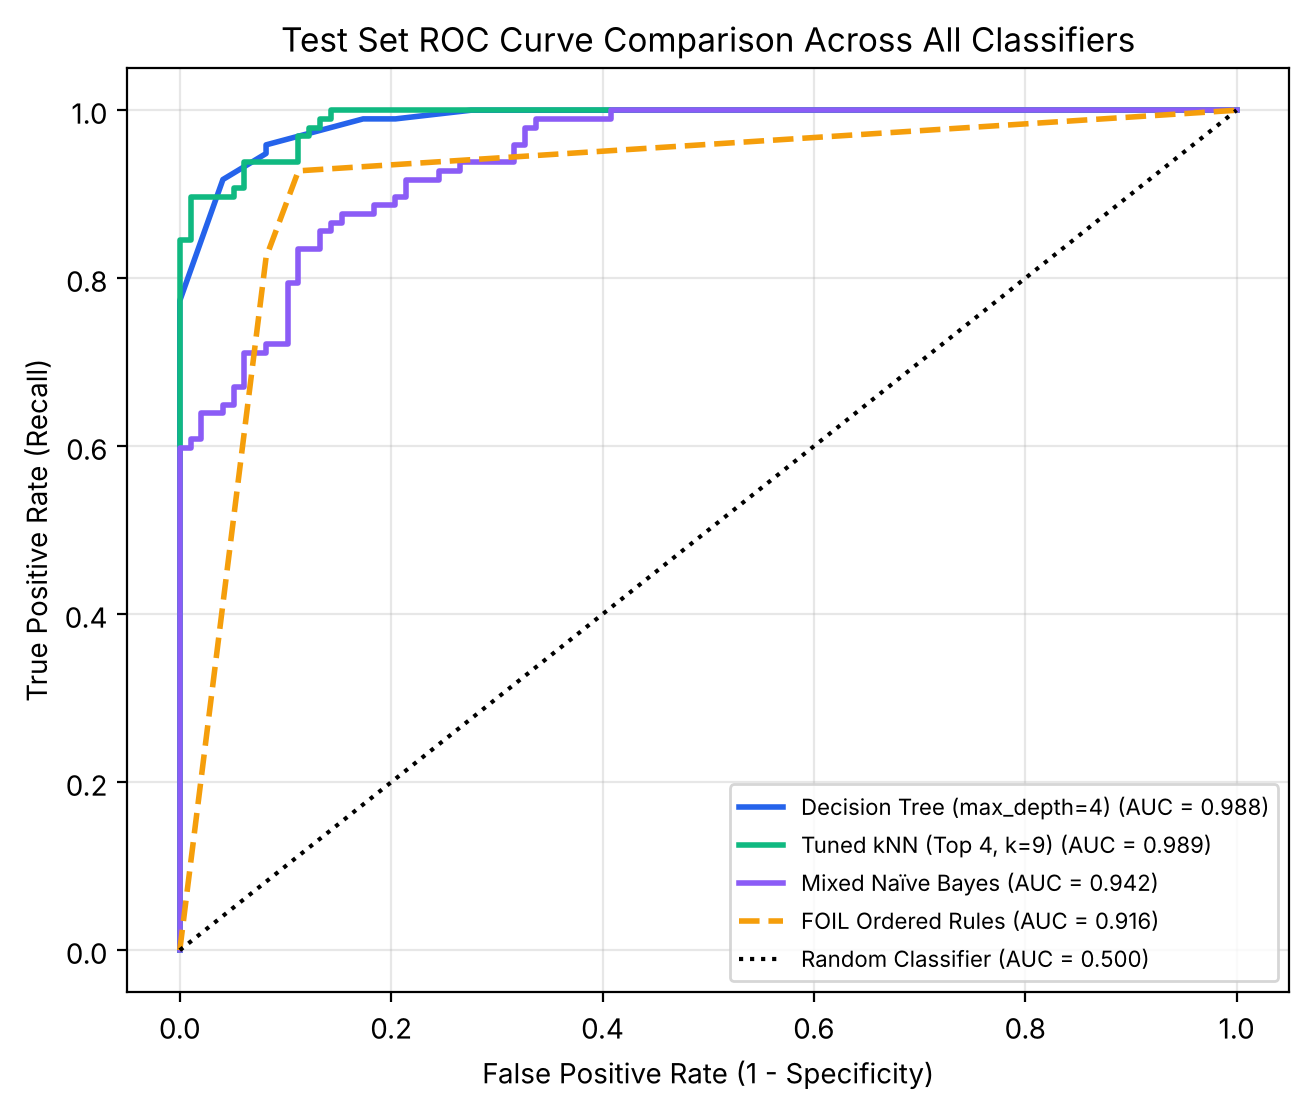

In [41]:
p_dt = dt.predict_proba(Xte_dt)[:, 1]
p_knn = knn.predict_proba(Xte_k[top4])[:, 1]
results = pd.DataFrame([report('Decision Tree (max_depth=4)', y_test, dt.predict(Xte_dt), p_dt),
                        report('Tuned kNN (Top 4, k=9)', y_test, knn.predict(Xte_k[top4]), p_knn),
                        rules_res, nb_res]).set_index('Model')
display((results * 100).round(1).assign(**{'ROC AUC': results['ROC AUC'].round(3)}))
print(f'Decision Tree vs k-NN: {round((results.Accuracy.iloc[0] - results.Accuracy.iloc[1]) * len(y_test))} test session apart')

plt.figure(figsize=(7.5, 6))
for (name, p), c, ls in zip([('Decision Tree (max_depth=4)', p_dt), ('Tuned kNN (Top 4, k=9)', p_knn),
                             ('Mixed Naïve Bayes', p_nb), ('FOIL Ordered Rules', score_rules)],
                            ['#2563eb', '#10b981', '#8b5cf6', '#f59e0b'], ['-', '-', '-', '--']):
    f, tp, _ = roc_curve(y_test, p); plt.plot(f, tp, ls, color=c, lw=2, label=f'{name} (AUC = {auc(f, tp):.3f})')
plt.plot([0, 1], [0, 1], 'k:', label='Random Classifier (AUC = 0.500)')
plt.xlabel('False Positive Rate (1 - Specificity)'); plt.ylabel('True Positive Rate (Recall)')
plt.title('Test Set ROC Curve Comparison Across All Classifiers'); plt.legend(loc='lower right', fontsize=8); plt.grid(alpha=.3); plt.show()

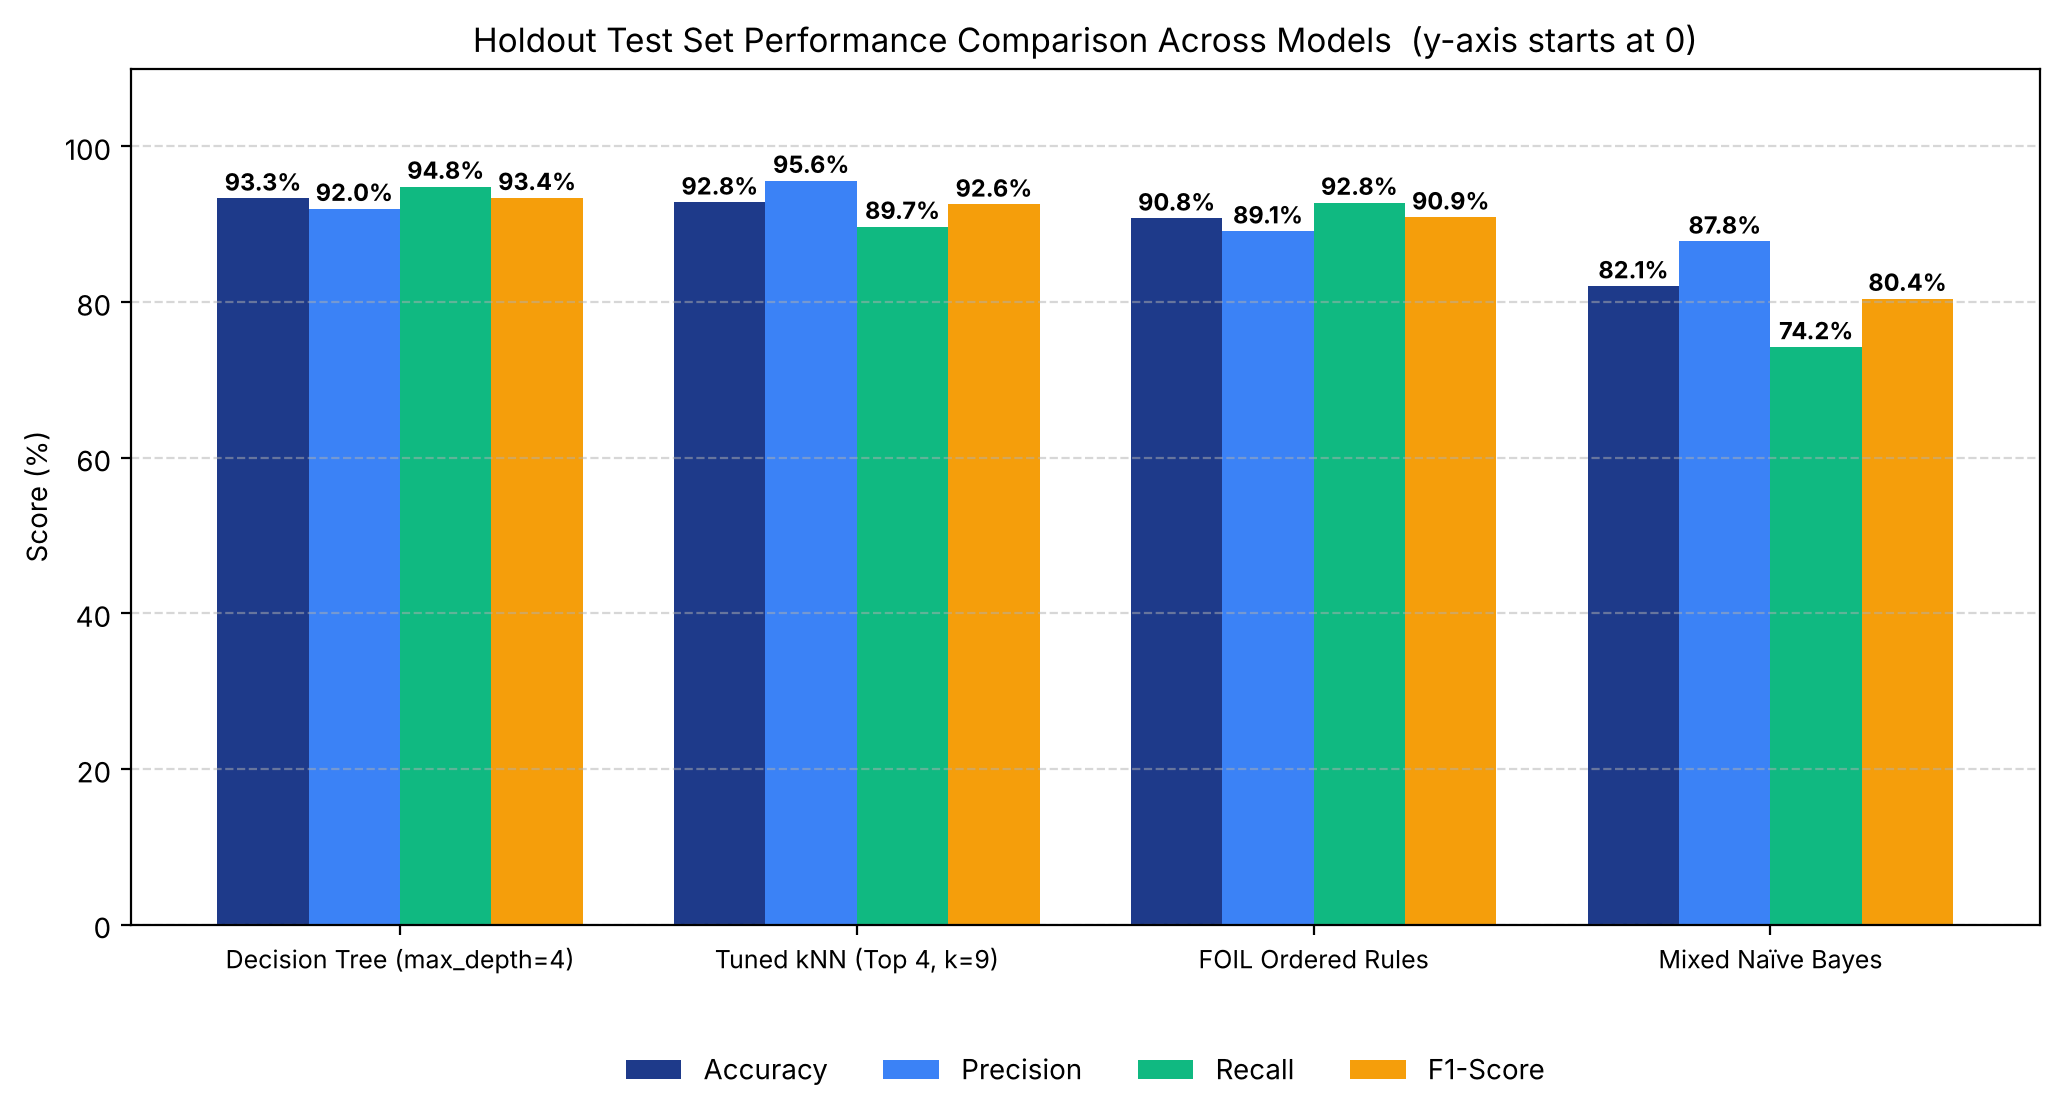

In [42]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
xx = np.arange(len(results)); w = 0.2
fig, ax = plt.subplots(figsize=(10.4, 5.7))
for i, (m, c) in enumerate(zip(metrics, ['#1e3a8a', '#3b82f6', '#10b981', '#f59e0b'])):
    bars = ax.bar(xx + (i - 1.5) * w, results[m] * 100, w, label=m if m != 'F1' else 'F1-Score', color=c)
    for b in bars: ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f'{b.get_height():.1f}%', ha='center', fontsize=8.5, fontweight='bold')
ax.set_ylim(0, 110); ax.set_ylabel('Score (%)'); ax.set_xticks(xx); ax.set_xticklabels(results.index, fontsize=9)
ax.set_title('Holdout Test Set Performance Comparison Across Models  (y-axis starts at 0)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False); ax.grid(axis='y', ls='--', alpha=.5)
plt.tight_layout(); plt.show()

## 3.6 Association Analysis: Apriori (slides 15–17)
Continuous measures are split at the median and combined with Workout_Type and Experience_Level into a 973 × 15 boolean matrix. Uses `mlxtend` (`pip install mlxtend`).

In [43]:
from mlxtend.frequent_patterns import apriori, association_rules

def med_split(col, hi, lo, hi_is_greater=True):
    m = data[col].median()
    return (data[col] > m, data[col] <= m) if hi_is_greater else (data[col] <= m, data[col] > m)

basket = pd.DataFrame(index=data.index)
basket['Duration=Long'], basket['Duration=Short'] = med_split('Session_Duration (hours)', 'Long', 'Short')
basket['AvgBPM=High'], basket['AvgBPM=Moderate'] = med_split('Avg_BPM', 'High', 'Moderate')
basket['BodyFat=Lower'], basket['BodyFat=Higher'] = med_split('Fat_Percentage', 'Lower', 'Higher', hi_is_greater=False)
basket['Calories=High'], basket['Calories=Low'] = med_split('Calories_Burned', 'High', 'Low')
for wt in sorted(data['Workout_Type'].unique()):
    basket[f'Workout={wt}'] = data['Workout_Type'] == wt
for lvl, name in [(1, 'Beginner'), (2, 'Intermediate'), (3, 'Expert')]:
    basket[f'Exp={name}'] = data['Experience_Level'] == lvl
print('Transaction matrix:', basket.shape)

itemsets = apriori(basket, min_support=0.15, use_colnames=True)
print('Frequent itemsets (min_support >= 0.15):', len(itemsets))

rules = association_rules(itemsets, metric='confidence', min_threshold=0.6)
rules = rules[rules['lift'] > 1.2].copy()
rules['IS'] = rules['support'] / np.sqrt(rules['antecedent support'] * rules['consequent support'])   # cosine
rules = rules.sort_values('IS', ascending=False)
fmt = lambda s: '{' + ', '.join(sorted(s)) + '}'
top = rules.head(10).assign(rule=lambda r: r.antecedents.map(fmt) + ' -> ' + r.consequents.map(fmt))
display(top[['rule', 'support', 'confidence', 'lift', 'IS']].round(3))

Transaction matrix: (973, 15)
Frequent itemsets (min_support >= 0.15): 80


,rule,support,confidence,lift,IS
7,{Calories=Low} -> {Duration=Short},0.433,0.864,1.727,0.864
8,{Duration=Short} -> {Calories=Low},0.433,0.864,1.727,0.864
2,{Duration=Long} -> {Calories=High},0.432,0.864,1.730,0.864
3,{Calories=High} -> {Duration=Long},0.432,0.864,1.730,0.864
89,"{Exp=Expert} -> {BodyFat=Lower, Calories=High,...",0.196,1.000,3.426,0.820
82,"{BodyFat=Lower, Calories=High, Duration=Long} ...",0.196,0.673,3.426,0.820
33,"{BodyFat=Lower, Duration=Long} -> {Exp=Expert}",0.196,0.628,3.201,0.793
88,"{Calories=High, Exp=Expert} -> {BodyFat=Lower,...",0.196,1.000,3.201,0.793
85,"{BodyFat=Lower, Duration=Long} -> {Calories=Hi...",0.196,0.628,3.201,0.793
36,"{Exp=Expert} -> {BodyFat=Lower, Duration=Long}",0.196,1.000,3.201,0.793


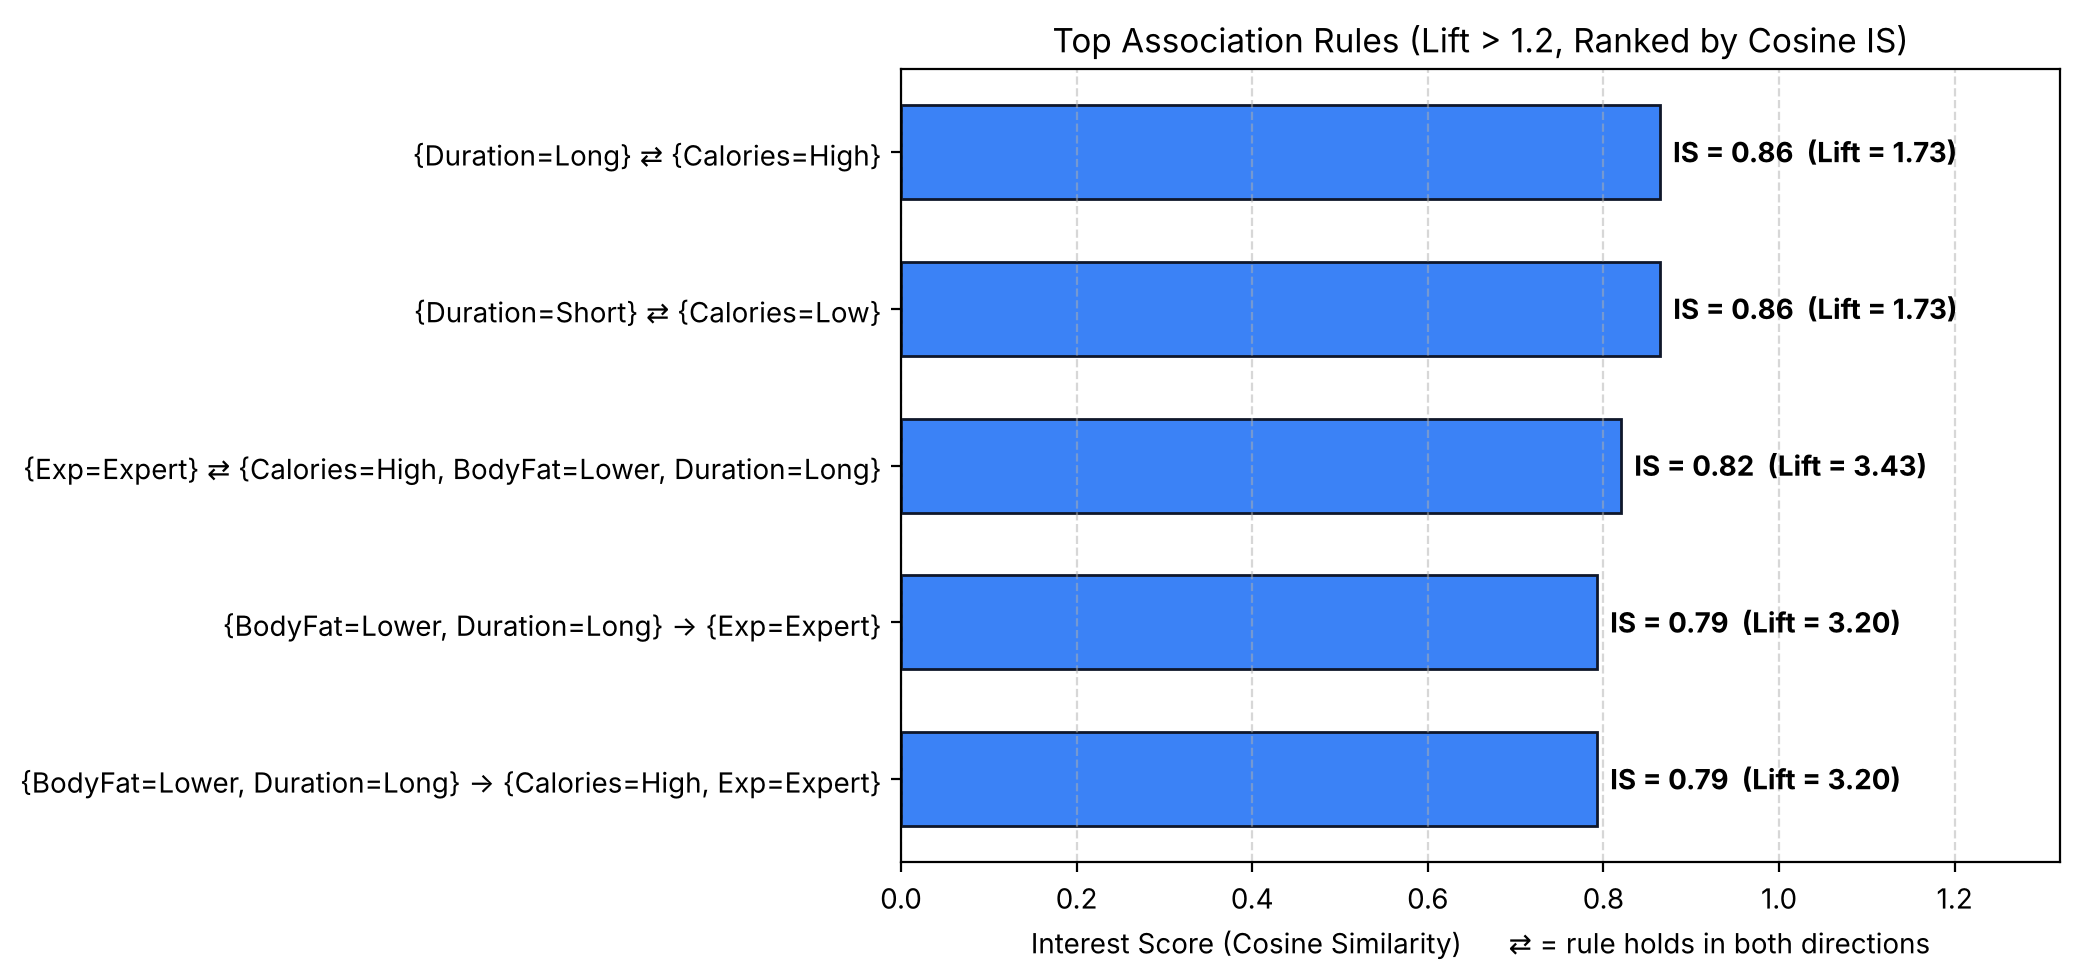

In [44]:
# Chart (slide 16): rules that hold both ways (same lift and IS) are shown once with ⇄
shown = [('{Duration=Long} ⇄ {Calories=High}', 0), ('{Duration=Short} ⇄ {Calories=Low}', 0),
         ('{Exp=Expert} ⇄ {Calories=High, BodyFat=Lower, Duration=Long}', 0),
         ('{BodyFat=Lower, Duration=Long} → {Exp=Expert}', 0), ('{BodyFat=Lower, Duration=Long} → {Calories=High, Exp=Expert}', 0)]
def lookup(a, c):
    r = rules[(rules.antecedents == frozenset(a)) & (rules.consequents == frozenset(c))].iloc[0]
    return r.IS, r.lift
vals = [lookup({'Duration=Long'}, {'Calories=High'}), lookup({'Duration=Short'}, {'Calories=Low'}),
        lookup({'Exp=Expert'}, {'Calories=High', 'BodyFat=Lower', 'Duration=Long'}),
        lookup({'BodyFat=Lower', 'Duration=Long'}, {'Exp=Expert'}),
        lookup({'BodyFat=Lower', 'Duration=Long'}, {'Calories=High', 'Exp=Expert'})]
fig, ax = plt.subplots(figsize=(10.5, 5)); yy = np.arange(len(shown))[::-1]
ax.barh(yy, [v[0] for v in vals], height=0.6, color='#3b82f6', edgecolor='#0f172a')
for yi, (is_, lift) in zip(yy, vals): ax.text(is_ + 0.015, yi, f'IS = {is_:.2f}  (Lift = {lift:.2f})', va='center', fontweight='bold')
ax.set_yticks(yy); ax.set_yticklabels([s[0] for s in shown]); ax.set_xlim(0, 1.32)
ax.set_xlabel('Interest Score (Cosine Similarity)      ⇄ = rule holds in both directions')
ax.set_title('Top Association Rules (Lift > 1.2, Ranked by Cosine IS)'); ax.grid(axis='x', ls='--', alpha=.5)
plt.tight_layout(); plt.show()

f11=420  f10=66  f01=66  f00=421
Odds ratio 40.59 | Lift 1.73 | Cosine IS 0.86 | On the diagonal: 86.4%


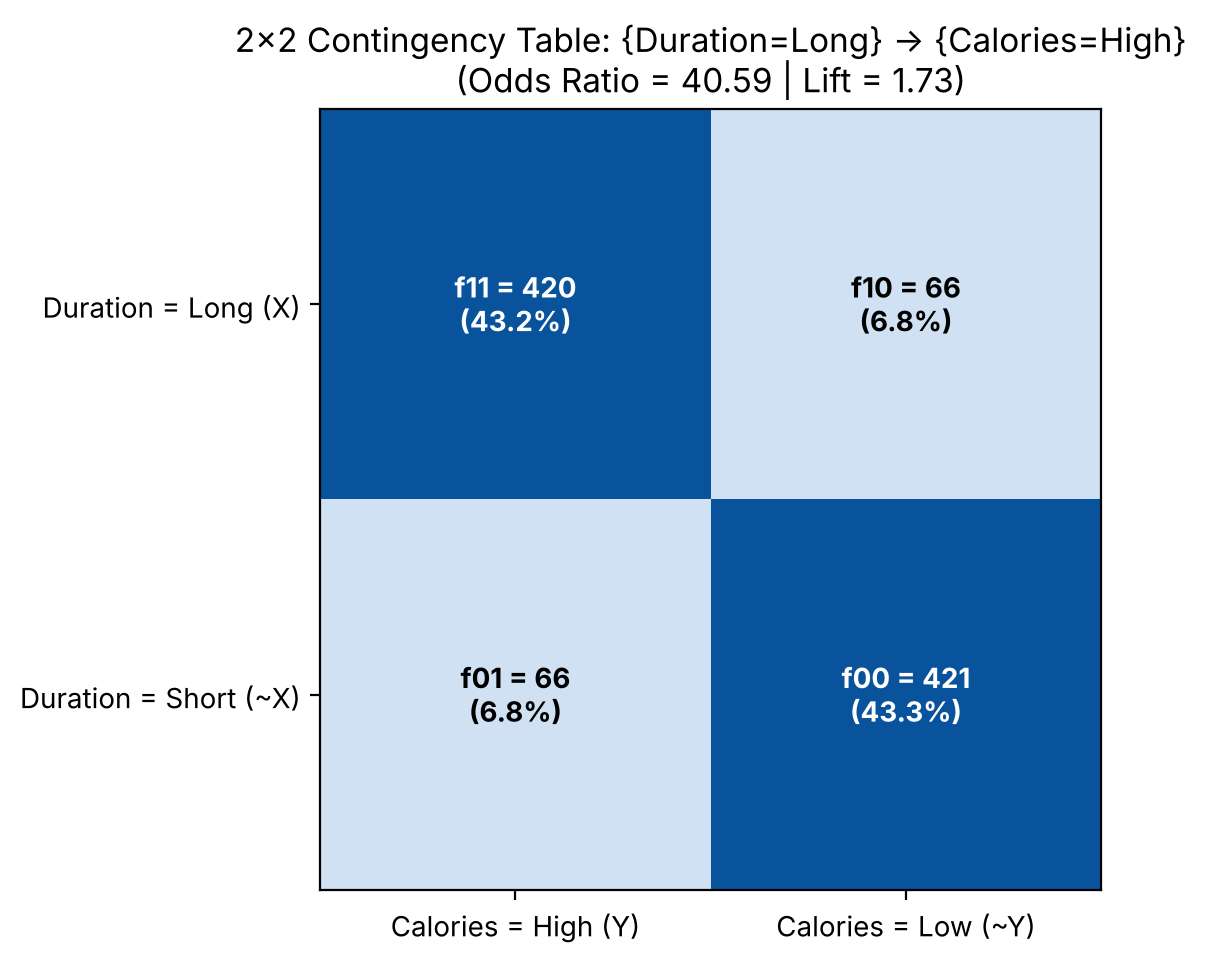

In [45]:
# 2x2 contingency table for {Duration=Long} -> {Calories=High} (slide 17)
X_, Y_ = basket['Duration=Long'], basket['Calories=High']
f11, f10 = int((X_ & Y_).sum()), int((X_ & ~Y_).sum())
f01, f00 = int((~X_ & Y_).sum()), int((~X_ & ~Y_).sum())
N = len(basket)
odds_ratio = (f11 * f00) / (f10 * f01)
lift = (f11 / N) / ((X_.mean()) * (Y_.mean()))
cosine = f11 / np.sqrt(X_.sum() * Y_.sum())
print(f'f11={f11}  f10={f10}  f01={f01}  f00={f00}')
print(f'Odds ratio {odds_ratio:.2f} | Lift {lift:.2f} | Cosine IS {cosine:.2f} | On the diagonal: {(f11 + f00) / N * 100:.1f}%')

fig, ax = plt.subplots(figsize=(5.5, 5))
M = np.array([[f11, f10], [f01, f00]])
ax.imshow(np.array([[1, 0], [0, 1]]), cmap='Blues', vmin=-0.3, vmax=1.2)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'f{1-i}{1-j} = {M[i, j]}\n({M[i, j] / N * 100:.1f}%)', ha='center', va='center',
                fontweight='bold', color='white' if i == j else 'black')
ax.set_xticks([0, 1]); ax.set_xticklabels(['Calories = High (Y)', 'Calories = Low (~Y)'])
ax.set_yticks([0, 1]); ax.set_yticklabels(['Duration = Long (X)', 'Duration = Short (~X)'])
ax.set_title(f'2x2 Contingency Table: {{Duration=Long}} -> {{Calories=High}}\n(Odds Ratio = {odds_ratio:.2f} | Lift = {lift:.2f})')
plt.tight_layout(); plt.show()

## 3.7 Summary

| Model | 5-fold CV (train) | Test accuracy | Notes |
|---|---|---|---|
| Decision Tree (depth 4) | 86.25% | 93.33% | Recommended: tied with k-NN, best recall, interpretable |
| k-NN (k=9, distance, top 4) | 91.52% | 92.82% | Highest precision and AUC |
| FOIL ordered rules | — | 90.77% | Just two rules + default |
| Mixed Naïve Bayes | 81.36% | 82.05% | Gaussian-only scores higher (85.13%) |

Every method points to the same driver: **session duration**, with heart rate, body fat and experience as secondary factors.